# **05 - Allelic Signature Validation and Coding Gene Recurrence**


Este notebook investiga a robustez das assinaturas alélicas associadas aos clados de *Candida auris* e sua distribuição em regiões codificantes do genoma.

Partimos dos agrupamentos genotípicos identificados no notebook anterior, utilizando os rótulos de clados fornecidos por especialistas para avaliar a consistência da ancoragem e a capacidade discriminativa dos marcadores alélicos.

A análise está organizada em três etapas principais:

1. **Validação cruzada das assinaturas alélicas:** avaliação da estabilidade da ancoragem e da classificação baseada em frequências alélicas, com separação dos rótulos de especialistas entre desenvolvimento e validação.
2. **Caracterização dos marcadores discriminativos:** identificação dos alelos associados a cada clado, utilizando diferenças de frequência alélica *one-vs-rest*.
3. **Anotação funcional e recorrência em genes codificantes:** integração com as anotações genômicas do arquivo GFF para identificar marcadores localizados em regiões codificantes e quantificar sua recorrência por gene.


O objetivo final é produzir tabelas de recorrência de marcadores por gene codificante, incluindo os dez genes mais recorrentes por clado, como base para interpretação biológica posterior.

## **Imports**

In [1]:
import re

import numpy as np
import pandas as pd

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)

## **5.1 Configuração**

In [2]:
from clade_clustering.paths import EXTERNAL_DIR, PROJECT_ROOT, RESULTS_DIR

SEED = 42
DATA_VERSION = "v4"

RESULTS_VERSION_DIR = RESULTS_DIR / DATA_VERSION

MATRICES_DIR = RESULTS_VERSION_DIR / "matrices" / "parsnp"
CLUSTERING_DIR = RESULTS_VERSION_DIR / "clustering"
CV_DIR = RESULTS_VERSION_DIR / "signature_cross_validation"

X_ENCODED_PATH = MATRICES_DIR / "X_encoded.parquet"
SAMPLE_METADATA_LABELED_PATH = MATRICES_DIR / "sample_metadata_labeled.parquet"
EXPERT_CLADE_LABELS_PATH = CLUSTERING_DIR / "expert_clade_labels.parquet"

# Hold-outs Ca e SRR, separados no notebook 04
X_ENCODED_HOLDOUT_PATH = MATRICES_DIR / "X_encoded_holdout.parquet"
SAMPLE_METADATA_HOLDOUT_PATH = MATRICES_DIR / "sample_metadata_holdout.parquet"

# Painel externo de mapeamento (30 genomas), gerado no notebook 03
MAPPING_MATRICES_DIR = RESULTS_VERSION_DIR / "matrices" / "mapping_panel"
X_MAPPING_GENOTYPES_PATH = MAPPING_MATRICES_DIR / "X_mapping_genotypes.parquet"
MAPPING_QC_PATH = MAPPING_MATRICES_DIR / "genotype_call_qc.csv"
MAPPING_IDS_PATH = EXTERNAL_DIR / "mapping_panel" / "IDs Cauris.xlsx"

EXTERNAL_PREDICTIONS_PATH = CV_DIR / "external_panel_predictions.csv"

GFF_PATH = (
    PROJECT_ROOT
    / "data/reference/annotations"
    / "GCF_003013715.1_ASM301371v2_genomic.gff"
)

if not GFF_PATH.exists():
    raise FileNotFoundError(
        f"Anotação GFF da referência não encontrada:\n{GFF_PATH}\n"
        "Baixe a anotação RefSeq de GCF_003013715.1 (B11220) com o "
        "NCBI Datasets CLI; os comandos estão no README, seção "
        "'Reference genome annotation'."
    )

## **5.2 Carregamento dos dados**

In [3]:
X_encoded = pd.read_parquet(X_ENCODED_PATH)
sample_metadata_df = pd.read_parquet(SAMPLE_METADATA_LABELED_PATH)
expert_labels = pd.read_parquet(EXPERT_CLADE_LABELS_PATH)

X_encoded_holdout = pd.read_parquet(X_ENCODED_HOLDOUT_PATH)
sample_metadata_holdout = pd.read_parquet(SAMPLE_METADATA_HOLDOUT_PATH)

assert X_encoded.index.equals(sample_metadata_df.index)

# X_encoded contém apenas os genomas de ajuste; Ca e SRR estão nos arquivos de hold-out
assert len(X_encoded) == 1243
assert X_encoded_holdout.index.equals(sample_metadata_holdout.index)
assert X_encoded_holdout.columns.equals(X_encoded.columns)
assert not X_encoded_holdout.index.isin(X_encoded.index).any()

print("X_encoded:", X_encoded.shape)
print("sample_metadata:", sample_metadata_df.shape)
print("Expert labels:", expert_labels.shape)
print("X_encoded_holdout:", X_encoded_holdout.shape)

X_encoded: (1243, 105317)
sample_metadata: (1243, 27)
Expert labels: (144, 2)
X_encoded_holdout: (11, 105317)


In [4]:
X_arr = X_encoded.to_numpy()
snp_names = X_encoded.columns.to_numpy()

In [5]:
X_arr = X_encoded.to_numpy(dtype=np.int8, copy=False)
snp_names = X_encoded.columns.to_numpy()

print("Matriz numérica:", X_arr.shape)
print("Identificadores alélicos:", snp_names.shape)

Matriz numérica: (1243, 105317)
Identificadores alélicos: (105317,)


### **5.2.1 Recuperação das amostras com rótulos expert**

In [6]:
expert_df = expert_labels.merge(
    sample_metadata_df[["cluster"]].reset_index(),
    on="accession",
    how="inner",
    validate="one_to_one",
)

expert_summary = (
    expert_df
    .groupby(["clade", "cluster"])
    .agg(n=("accession", "size"))
    .sort_index()
)

print("Experts cruzados:", len(expert_df))
display(expert_summary)

Experts cruzados: 144


,,n
clade,cluster,
I,0,113
II,3,6
III,1,13
IV,2,8
V,4,1
VI,5,3


## **5.3 Funções auxiliares para a validação cruzada**

In [7]:
HIGH = 0.8
LOW = 0.2

CV_CLADES = ["I", "II", "III", "IV"]
ALL_CLADES = ["I", "II", "III", "IV", "V", "VI"]

N_SPLITS = 3
N_REPEATS = 5

### **5.3.1 Ancoragem parcial**

constrói um dicionário cluster → clado utilizando apenas os experts disponíveis para ancoragem naquele fold. Os expert de validação não participam desse mapeamento.

In [8]:
def build_cluster_to_clade(anchor_train):
    mapping = (
        anchor_train.groupby("cluster")["clade"]
        .agg(lambda values: values.value_counts().idxmax())
        .to_dict()
    )

    mapped_formal = {
        cluster: clade
        for cluster, clade in mapping.items()
        if clade in CV_CLADES
    }

    missing_clades = set(CV_CLADES) - set(mapped_formal.values())

    if missing_clades:
        raise ValueError(
            f"Fold sem âncoras para os clados: {missing_clades}"
        )

    if len(set(mapped_formal.values())) != len(mapped_formal):
        raise ValueError("Dois clusters associados ao mesmo clado.")

    return mapped_formal

### **5.3.2 Descoberta das assinaturas alélicas**

Esta função se baseia no procedimento  one-vs-rest: para cada clado, comparamos a frequência de presença de cada indicador alélico com a frequência em todos os demais clados considerados.

A função retorna dois objetos:
- panel: dicionário dos índices dos marcadores diretos e inversos por clado.
- panel_df: tabela detalhada dos marcadores, contendo frequências, diferença $\Delta$ e identificadores dos alelos.

In [9]:
def discover_panel(X_train, y_train, clades):
    panel = {}
    panel_rows = []

    for clade in clades:
        mask_in = y_train == clade
        mask_out = ~mask_in

        if mask_in.sum() == 0 or mask_out.sum() == 0:
            continue

        freq_in = X_train[mask_in].mean(axis=0)
        freq_out = X_train[mask_out].mean(axis=0)
        delta = freq_in - freq_out

        direct_idx = np.where(
            (freq_in >= HIGH) & (freq_out <= LOW)
        )[0]

        inverse_idx = np.where(
            (freq_in <= LOW) & (freq_out >= HIGH)
        )[0]

        panel[clade] = {
            "direct": direct_idx,
            "inverse": inverse_idx,
        }

        for direction, indices in (
            ("direct", direct_idx),
            ("inverse", inverse_idx),
        ):
            for idx in indices:
                panel_rows.append({
                    "clade": clade,
                    "direction": direction,
                    "marker_idx": int(idx),
                    "snp_name": snp_names[idx],
                    "freq_in": float(freq_in[idx]),
                    "freq_out": float(freq_out[idx]),
                    "delta": float(delta[idx]),
                })

    panel_df = (
        pd.DataFrame(panel_rows)
        .sort_values("delta", ascending=False)
        .reset_index(drop=True)
    )

    return panel, panel_df

### **5.3.3 Matriz de scores**

A função atribui a cada genoma uma pontuação entre 0 e 1 para cada clado, calculada como a proporção de condições da assinatura satisfeitas.

A matriz possui amostras nas linhas e clados nas colunas. A classe predita é a de maior score e uma margem é avaliada.

In [10]:
def score_samples(X, panel, clades):
    scores = np.zeros(
        (len(X), len(clades)),
        dtype=np.float32,
    )

    for col_idx, clade in enumerate(clades):
        if clade not in panel:
            continue

        direct_idx = panel[clade]["direct"]
        inverse_idx = panel[clade]["inverse"]

        total = len(direct_idx) + len(inverse_idx)

        if total == 0:
            continue

        direct_hits = (
            X[:, direct_idx].sum(axis=1)
            if len(direct_idx)
            else np.zeros(len(X))
        )

        inverse_hits = (
            (1 - X[:, inverse_idx]).sum(axis=1)
            if len(inverse_idx)
            else np.zeros(len(X))
        )

        scores[:, col_idx] = (
            direct_hits + inverse_hits
        ) / total

    return scores

## **5.4 Validação cruzada**

### **5.4.1 Preparação dos conjuntos**

A descoberta dos marcadores alélicos não pode usar os experts de validação. O conjunto de desenvolvimento recebe rótulos por meio da ancoragem dos clusters.

In [11]:
expert_formal = expert_df[
    expert_df["clade"].isin(CV_CLADES)
].copy()

ca_mask = (
    sample_metadata_df["vcf_sample"]
    .str.startswith("Ca", na=False)
    .to_numpy()
)

expert_accessions = set(expert_df["accession"])
expert_mask_all = sample_metadata_df.index.isin(expert_accessions)

development_base_mask = ~expert_mask_all & ~ca_mask

print("Experts disponíveis para CV:")
display(
    expert_formal["clade"]
    .value_counts()
    .reindex(CV_CLADES)
    .rename("n_experts")
    .to_frame()
)

print("Amostras candidatas ao desenvolvimento:",
      int(development_base_mask.sum()))

Experts disponíveis para CV:


,n_experts
clade,
I,113
II,6
III,13
IV,8


Amostras candidatas ao desenvolvimento: 1099


### **5.4.2 Execução da validação cruzada**

In [12]:
splitter = RepeatedStratifiedKFold(
    n_splits=N_SPLITS,
    n_repeats=N_REPEATS,
    random_state=SEED,
)

fold_rows = []
prediction_rows = []
panel_size_rows = []

y_expert = expert_formal["clade"].to_numpy()
X_dummy = np.zeros((len(expert_formal), 1))

for fold_id, (anchor_idx, validation_idx) in enumerate(
    splitter.split(X_dummy, y_expert), start=1
):
    anchor_train = expert_formal.iloc[anchor_idx]
    expert_validation = expert_formal.iloc[validation_idx]

    # 1. Ancoragem parcial
    fold_mapping = build_cluster_to_clade(anchor_train)

    # 2. Seleção de genomas não expert dos clusters mapeados
    development_mask = (
        development_base_mask
        & sample_metadata_df["cluster"].isin(fold_mapping).to_numpy()
    )

    X_development = X_arr[development_mask]

    y_development = (
        sample_metadata_df.loc[development_mask, "cluster"]
        .map(fold_mapping)
        .to_numpy()
    )

    # 3. Descoberta das assinaturas
    panel, panel_df = discover_panel(
        X_development,
        y_development,
        CV_CLADES,
    )

    # 4. Predição dos experts reservados
    validation_accessions = expert_validation["accession"].tolist()

    X_validation = X_encoded.loc[validation_accessions].to_numpy(
        dtype=np.int8, copy=False
    )
    y_validation = expert_validation["clade"].to_numpy()

    validation_clusters = expert_validation["cluster"].to_numpy()
    y_pred_anchor = np.array([
        fold_mapping[int(c)] for c in validation_clusters
    ])

    scores = score_samples(X_validation, panel, CV_CLADES)

    y_pred = np.array(CV_CLADES)[scores.argmax(axis=1)]

    ordered_scores = np.sort(scores, axis=1)[:, ::-1]
    margins = ordered_scores[:, 0] - ordered_scores[:, 1]

    # 5. Métricas do fold
    fold_rows.append({
        "fold": fold_id,
        "n_anchor": len(anchor_train),
        "n_validation": len(expert_validation),
        "n_development": len(y_development),
        "acc_anchor": accuracy_score(y_validation, y_pred_anchor),
        "accuracy": accuracy_score(y_validation, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_validation, y_pred),
        "f1_macro": f1_score(
            y_validation, y_pred,
            labels=CV_CLADES,
            average="macro",
            zero_division=0,
        ),
        "mean_margin": float(margins.mean()),
        "concordance_anchor_allelic": float(
            (y_pred_anchor == y_pred).mean()
        ),
        "cluster_to_clade": str(fold_mapping),
    })

    # 6. Dimensões dos painéis
    for clade in CV_CLADES:
        panel_clade = panel[clade]

        n_direct = len(panel_clade["direct"])
        n_inverse = len(panel_clade["inverse"])

        panel_size_rows.append({
            "fold": fold_id,
            "clade": clade,
            "n_direct": n_direct,
            "n_inverse": n_inverse,
            "n_total": n_direct + n_inverse,
        })

    # 7. Predições individuais dos experts
    for i, accession in enumerate(validation_accessions):
        record = {
            "fold": fold_id,
            "accession": accession,
            "clade_true": y_validation[i],
            "clade_pred_anchor": y_pred_anchor[i],
            "clade_pred": y_pred[i],
            "best_score": float(ordered_scores[i, 0]),
            "margin": float(margins[i]),
        }

        for j, clade in enumerate(CV_CLADES):
            record[f"score_{clade}"] = float(scores[i, j])

        prediction_rows.append(record)

fold_metrics_df = pd.DataFrame(fold_rows)
panel_sizes_df = pd.DataFrame(panel_size_rows)
cv_predictions_long_df = pd.DataFrame(prediction_rows)

print("Validação cruzada concluída.")

Validação cruzada concluída.


Em cada fold:

1. Parte dos experts nomeia os clusters.
2. Os genomas não expert fornecem as frequências alélicas para construir as assinaturas.
3. Os experts reservados recebem previsões tanto pela ancoragem quanto pela matriz de scores.
4. Registramos as métricas de classificação, as margens e o tamanho dos painéis.

In [13]:
metric_columns = [
    "acc_anchor",
    "accuracy",
    "balanced_accuracy",
    "f1_macro",
    "mean_margin",
    "concordance_anchor_allelic",
]

fold_summary_df = (
    fold_metrics_df[metric_columns]
    .agg(["mean", "std", "min", "max"])
    .T
)

display(fold_summary_df.round(4))

,mean,std,min,max
acc_anchor,1.0000,0.0000,1.0000,1.0000
accuracy,1.0000,0.0000,1.0000,1.0000
balanced_accuracy,1.0000,0.0000,1.0000,1.0000
f1_macro,1.0000,0.0000,1.0000,1.0000
mean_margin,0.9438,0.0047,0.9392,0.9512
concordance_anchor_allelic,1.0000,0.0000,1.0000,1.0000


### **5.4.3 Dimensão dos painéis ao longo dos folds**

In [14]:
panel_size_summary = (
    panel_sizes_df
    .groupby("clade")[["n_direct", "n_inverse", "n_total"]]
    .agg(["mean", "std", "min", "max"])
    .round(1)
)

display(panel_size_summary)

n_direct                    n_inverse                   n_total       \
          mean  std    min    max      mean  std   min   max     mean  std   
clade                                                                        
I       3200.0  0.0   3200   3200     276.0  0.0   276   276   3476.0  0.0   
II       627.0  0.0    627    627    7093.0  0.0  7093  7093   7720.0  0.0   
III     3212.0  0.0   3212   3212    3472.0  0.0  3472  3472   6684.0  0.0   
IV     23849.0  0.0  23849  23849    4455.0  0.0  4455  4455  28304.0  0.0   

                     
         min    max  
clade                
I       3476   3476  
II      7720   7720  
III     6684   6684  
IV     28304  28304

Para cada clado, verificamos quantos indicadores alélicos satisfizeram os critérios de assinatura direta ou inversa em cada fold.

- n_direct: indicadores característicos pela presença.
- n_inverse: indicadores característicos pela ausência.
- n_total: soma das duas categorias.

### **5.4.5 Consenso dos expert entre repetições**

In [15]:
expert_consensus_df = (
    cv_predictions_long_df
    .groupby(["accession", "clade_true"], as_index=False)
    .agg(
        clade_pred=(
            "clade_pred",
            lambda s: s.value_counts().idxmax(),
        ),
        vote_fraction=(
            "clade_pred",
            lambda s: s.value_counts(normalize=True).max(),
        ),
        mean_best_score=("best_score", "mean"),
        mean_margin=("margin", "mean"),
        n_validations=("fold", "count"),
    )
)

expert_consensus_df["correct"] = (
    expert_consensus_df["clade_true"]
    == expert_consensus_df["clade_pred"]
)

display(expert_consensus_df.head())

,accession,clade_true,clade_pred,vote_fraction,mean_best_score,mean_margin,n_validations,correct
0,GCA_002759435.3,I,I,1.0,0.979574,0.968952,5,True
1,GCA_003014415.1,IV,IV,1.0,0.999894,0.498248,5,True
2,GCA_004287075.1,I,I,1.0,1.000000,0.999965,5,True
3,GCA_007168705.1,II,II,1.0,1.000000,0.480102,5,True
4,GCA_008275145.1,IV,IV,1.0,0.999505,0.498009,5,True


Agrupa as cinco previsões de cada expert e calcula:

- clade_pred: clado mais frequentemente previsto.
- vote_fraction: fração das repetições que concordaram com essa previsão.
- mean_best_score: score médio da classe vencedora.
- mean_margin: margem média entre os dois maiores scores.
- correct: se a predição por consenso corresponde ao clado conhecido.

É importante distinguir vote_fraction de mean_margin: podemos ter cinco previsões concordantes, mas margens relativamente pequenas.

### **5.4.6 Relatório por consenso e instabilidades**

In [16]:
from sklearn.metrics import classification_report, confusion_matrix

print("Classificação por consenso:")
print(
    classification_report(
        expert_consensus_df["clade_true"],
        expert_consensus_df["clade_pred"],
        labels=CV_CLADES,
        zero_division=0,
    )
)

consensus_cm_df = pd.DataFrame(
    confusion_matrix(
        expert_consensus_df["clade_true"],
        expert_consensus_df["clade_pred"],
        labels=CV_CLADES,
    ),
    index=[f"real_{c}" for c in CV_CLADES],
    columns=[f"pred_{c}" for c in CV_CLADES],
)

display(consensus_cm_df)

unstable = expert_consensus_df.loc[
    (expert_consensus_df["vote_fraction"] < 1)
    | (~expert_consensus_df["correct"])
]

print(f"Experts com predição instável ou incorreta: {len(unstable)}")
display(unstable)

Classificação por consenso:
              precision    recall  f1-score   support

           I       1.00      1.00      1.00       113
          II       1.00      1.00      1.00         6
         III       1.00      1.00      1.00        13
          IV       1.00      1.00      1.00         8

    accuracy                           1.00       140
   macro avg       1.00      1.00      1.00       140
weighted avg       1.00      1.00      1.00       140



,pred_I,pred_II,pred_III,pred_IV
real_I,113,0,0,0
real_II,0,6,0,0
real_III,0,0,13,0
real_IV,0,0,0,8


Experts com predição instável ou incorreta: 0


,accession,clade_true,clade_pred,vote_fraction,mean_best_score,mean_margin,n_validations,correct


## **5.5 Construção do painel alélico final**

### **5.5.1 Mapeamento e conjunto de desenvolvimento**

Atribuímos os rótulos de clado aos genomas sem classificação expert, utilizando os clusters identificados no notebook 04.

Diferentemente da CV, não precisamos reconstruir o mapeamento a cada fold: usamos a ancoragem completa.

In [17]:
# Mapeamento final dos seis clusters
assert expert_df.groupby("cluster")["clade"].nunique().eq(1).all()

final_mapping = (
    expert_df.groupby("cluster")["clade"]
    .first()
    .to_dict()
)

assert set(final_mapping.values()) == set(ALL_CLADES)

# Todas as amostras Ca e SRR são hold-out
manual_mask = (
    sample_metadata_df["vcf_sample"]
    .str.match(r"(?i)^(?:Ca\d+|SRR\d+)", na=False)
    .to_numpy()
)

# Exclui experts e amostras hold-out da descoberta
final_development_mask = (
    ~expert_mask_all
    & ~manual_mask
    & sample_metadata_df["cluster"].isin(final_mapping).to_numpy()
)

X_final_development = X_arr[final_development_mask]

y_final_development = (
    sample_metadata_df.loc[final_development_mask, "cluster"]
    .map(final_mapping)
    .to_numpy()
)

# Ca e SRR já foram separadas no notebook 04: a máscara deve estar vazia
assert not manual_mask.any(), "Ca/SRR encontradas na matriz de treinamento"

print("Amostras hold-out na matriz de treinamento:", manual_mask.sum())
print("Genomas de desenvolvimento:", len(y_final_development))

Amostras hold-out na matriz de treinamento: 0
Genomas de desenvolvimento: 1099


### **5.5.2 Construção do pool e descoberta das assinaturas**

Para cada clado, calculamos a frequência de cada indicador alélico dentro e fora dele. A função discover_panel aplica os limiares HIGH=0.8 e LOW=0.2 para identificar marcadores diretos e inversos.

A principal diferença agora é que o rest inclui todos os outros cinco clados.

In [18]:
X_experts = X_encoded.loc[
    expert_df["accession"]
].to_numpy(dtype=np.int8, copy=False)

y_experts = expert_df["clade"].to_numpy()

X_pool = np.vstack([
    X_final_development,
    X_experts,
])

y_pool = np.concatenate([
    y_final_development,
    y_experts,
])

final_panel, final_panel_df = discover_panel(
    X_pool,
    y_pool,
    ALL_CLADES,
)

print("Pool:", X_pool.shape)
display(pd.Series(y_pool).value_counts().sort_index())

Pool: (1243, 105317)


I      890
II      83
III    225
IV      41
V        1
VI       3
Name: count, dtype: int64

### **5.5.3 Dimensão das assinaturas por clado**

Aqui quantificamos o número de indicadores alélicos discriminativos encontrados para cada clado.

Atenção: esses números representam marker features, não posições genômicas únicas. Loci multialélicos podem gerar mais de um indicador, distinção que será importante na análise de recorrência por gene.

In [19]:
final_panel_summary_df = pd.DataFrame([
    {
        "clade": clade,
        "n_direct": len(final_panel[clade]["direct"]),
        "n_inverse": len(final_panel[clade]["inverse"]),
        "n_total": (
            len(final_panel[clade]["direct"])
            + len(final_panel[clade]["inverse"])
        ),
    }
    for clade in ALL_CLADES
]).set_index("clade")

display(final_panel_summary_df)

,n_direct,n_inverse,n_total
clade,,,
I,3200,276,3476
II,730,8021,8751
III,3212,3472,6684
IV,23855,4457,28312
V,45326,6182,51508
VI,23059,4415,27474


### **5.5.4 Classificação alélica sobre amostras hold out**

Cada genoma recebe seis scores, um para cada clado. A classe predita corresponde ao maior score, e a margem mede a diferença entre os dois maiores.

As amostras Ca e SRR vêm de `X_encoded_holdout` e `sample_metadata_holdout` (notebook 04): não participaram da PCA, do KMeans nem da descoberta das assinaturas. `clade_assigned` é o clado atribuído pelo KMeans ajustado no notebook 04.

In [20]:
# Amostras manuais (Ca e SRR): hold-outs do notebook 04
manual_info = sample_metadata_holdout[
    ["vcf_sample", "cluster", "clade_assigned"]
].copy()

# Matriz genotípica correspondente
X_manual = X_encoded_holdout.loc[
    manual_info.index
].to_numpy(dtype=np.int8, copy=False)

# Classificação pela assinatura alélica
scores_manual = score_samples(
    X_manual,
    final_panel,
    ALL_CLADES,
)

ordered_scores = np.sort(scores_manual, axis=1)[:, ::-1]

manual_info["clade_by_alleles"] = (
    np.array(ALL_CLADES)[scores_manual.argmax(axis=1)]
)

manual_info["best_score"] = ordered_scores[:, 0]
manual_info["margin"] = (
    ordered_scores[:, 0] - ordered_scores[:, 1]
)

manual_info["concordant"] = (
    manual_info["clade_assigned"]
    == manual_info["clade_by_alleles"]
)

for j, clade in enumerate(ALL_CLADES):
    manual_info[f"score_{clade}"] = scores_manual[:, j]

display(manual_info.reset_index())

,accession,vcf_sample,cluster,clade_assigned,clade_by_alleles,best_score,margin,concordant,score_I,score_II,score_III,score_IV,score_V,score_VI
0,Ca14.fasta,Ca14.fasta,2,IV,IV,0.997528,0.158079,True,0.300921,0.312993,0.500449,0.997528,0.232605,0.839448
1,SRR9007776.pilon.fasta,SRR9007776.pilon.fasta,4,V,V,1.000000,0.509426,True,0.339183,0.370929,0.490575,0.446454,1.000000,0.432846
2,SRR18325430.pilon.fasta,SRR18325430.pilon.fasta,4,V,V,0.999165,0.508591,True,0.339183,0.370815,0.490575,0.447019,0.999165,0.433355
3,Ca9.fasta,Ca9.fasta,0,I,I,1.000000,0.999886,True,1.000000,0.000114,0.000000,0.000000,0.000000,0.000000
4,Ca10.fasta,Ca10.fasta,0,I,I,0.999712,0.999563,True,0.999712,0.000000,0.000150,0.000000,0.000000,0.000000
5,Ca13.fasta,Ca13.fasta,2,IV,IV,0.997422,0.158046,True,0.301208,0.312993,0.500299,0.997422,0.232624,0.839375
6,SRR18325431.pilon.fasta,SRR18325431.pilon.fasta,4,V,V,0.999068,0.508494,True,0.339183,0.370472,0.490575,0.446701,0.999068,0.433100
7,SRR18325432.pilon.fasta,SRR18325432.pilon.fasta,4,V,V,0.999126,0.508552,True,0.339183,0.370815,0.490575,0.447019,0.999126,0.433355
8,Ca12.fasta,Ca12.fasta,0,I,I,1.000000,1.000000,True,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9,Ca11.fasta,Ca11.fasta,0,I,I,1.000000,0.999314,True,1.000000,0.000686,0.000000,0.000071,0.000058,0.000000


In [21]:
CV_DIR.mkdir(parents=True, exist_ok=True)

manual_info.reset_index().to_csv(
    CV_DIR / "manual_samples_signature_predictions.csv",
    index=False,
)

## **5.6 Recurrent coding markers by clade**

A pergunta central é:

> Quais genes codificantes e produtos proteicos concentram, de forma recorrente, posições SNP discriminativas de cada um dos seis clados do painel final (`ALL_CLADES`)?

A anotação usa o painel final completo (I–VI); `CV_CLADES` (I–IV) fica restrito à validação cruzada. Atenção ao ler V e VI: o pool de descoberta tem apenas 1 e 3 genomas desses clados, então `freq_in` só assume poucos valores e os painéis incluem praticamente todo alelo privado desses genomas. A recorrência em V/VI reflete divergência de poucos genomas, não uma assinatura estimada sobre uma população.




### **5.6.1 Mapeamento entre identificadores: `GenBank` <-> `RefSeq`**

O arquivo `.vcf` utiliza arquivos fasta oriundos do `GenBank`, cujos identificadores `chrom` usam prefixo `CP_`. O arquivo `.gff` utiliza identificadores `NC_`.

In [22]:
CHROM_MAP = {
    "CP043531.1": "NC_072812.1",
    "CP043532.1": "NC_072813.1",
    "CP043533.1": "NC_072814.1",
    "CP043534.1": "NC_072815.1",
    "CP043535.1": "NC_072816.1",
    "CP043536.1": "NC_072817.1",
    "CP043537.1": "NC_072818.1",
}

### **5.6.2 Gerando um DataFrame a partir do arquivo .gff: apenas colunas de metadados relevantes**

In [23]:
_GFF_ATTR_KEYS = [
    "ID", "Parent", "Name", "Dbxref", "locus_tag",
    "gene_biotype", "product", "protein_id", "transcript_id", "chromosome",
]

def _parse_gff_attrs(attr_str):
    attrs = {}
    for part in attr_str.split(";"):
        if "=" not in part:
            continue
        k, v = part.split("=", 1)
        attrs[k.strip()] = v.strip()
    return attrs

_gff_rows = []
with open(GFF_PATH) as _f:
    for _line in _f:
        if _line.startswith("#"):
            continue
        _parts = _line.rstrip("\n").split("\t")
        if len(_parts) < 9:
            continue
        _attrs = _parse_gff_attrs(_parts[8])
        _row = {
            "seqid":          _parts[0],
            "source":         _parts[1],
            "feature_type":   _parts[2],
            "start":          int(_parts[3]),
            "end":            int(_parts[4]),
            "strand":         _parts[6],
            "attributes_raw": _parts[8],
        }
        for _k in _GFF_ATTR_KEYS:
            _row[_k] = _attrs.get(_k)
        _gff_rows.append(_row)

# NOME ANTIGO: gff_features_df
df_gff = pd.DataFrame(_gff_rows)
print(f"df_gff: {df_gff.shape}")

df_gff: (22962, 17)


- `gene`: extensão genômica total associada a um gene.
- `mRNA`: transcrito produzido a partir do gene.
- `éxon`: região mantida após splicing.
- `CDS`: partes do transcrito (dos éxons) que efetivamente são traduzidas em proteínas.


```text
gene/mRNA:  [--------------------------------]
éxon 1:     [--]
éxon 2:                    [------------------]
íntron:        [-----------]
```

In [24]:
df_gff.head()

,seqid,source,feature_type,start,end,strand,attributes_raw,ID,Parent,Name,Dbxref,locus_tag,gene_biotype,product,protein_id,transcript_id,chromosome
0,NC_072812.1,RefSeq,region,1,3148135,+,ID=NC_072812.1:1..3148135;Dbxref=taxon:498019;...,NC_072812.1:1..3148135,NaN,1,taxon:498019,NaN,NaN,NaN,NaN,NaN,1
1,NC_072812.1,RefSeq,gene,669,3041,+,ID=gene-CJI96_0000001;Dbxref=GeneID:79514224;N...,gene-CJI96_0000001,NaN,CJI96_0000001,GeneID:79514224,CJI96_0000001,protein_coding,NaN,NaN,NaN,NaN
2,NC_072812.1,RefSeq,mRNA,669,3041,+,ID=rna-XM_054702012.1;Parent=gene-CJI96_000000...,rna-XM_054702012.1,gene-CJI96_0000001,XM_054702012.1,"GeneID:79514224,GenBank:XM_054702012.1",CJI96_0000001,NaN,M28 family metallopeptidase,NaN,XM_054702012.1,NaN
3,NC_072812.1,RefSeq,exon,669,3041,+,ID=exon-XM_054702012.1-1;Parent=rna-XM_0547020...,exon-XM_054702012.1-1,rna-XM_054702012.1,NaN,"GeneID:79514224,GenBank:XM_054702012.1",CJI96_0000001,NaN,M28 family metallopeptidase,NaN,XM_054702012.1,NaN
4,NC_072812.1,RefSeq,CDS,669,3041,+,ID=cds-XP_054557987.1;Parent=rna-XM_054702012....,cds-XP_054557987.1,rna-XM_054702012.1,XP_054557987.1,"GeneID:79514224,GenBank:XP_054557987.1",CJI96_0000001,NaN,M28 family metallopeptidase,XP_054557987.1,NaN,NaN


### **5.6.3 DataFrame com todas colunas de metadados: análise restrita à cromossomo + comprimento**

In [25]:
def _parse_gff_attrs_full(attr_str):
    """Parse completo de attributes_raw — todas as chaves presentes, não só as de _GFF_ATTR_KEYS."""
    attrs = {}
    for part in attr_str.split(";"):
        if "=" not in part:
            continue
        k, v = part.split("=", 1)
        attrs[k.strip()] = v.strip()
    return attrs


def query_gff_region(seqid, start, end, overlap=True):
    """Todas as features do GFF no cromossomo `seqid` que se sobrepõem a [start, end]
    (ou que estão inteiramente contidas nele, se overlap=False), com todas as colunas
    de metadados presentes em attributes_raw expandidas dinamicamente — cada feature_type
    pode trazer colunas diferentes (mRNA tem transcript_id, CDS tem orig_transcript_id
    e transl_table, gene tem gbkey, etc.); colunas ausentes numa linha viram NaN."""
    sub = df_gff[df_gff["seqid"] == seqid]
    if overlap:
        mask = (sub["start"] <= end) & (sub["end"] >= start)
    else:
        mask = (sub["start"] >= start) & (sub["end"] <= end)
    sub = sub[mask]

    if sub.empty:
        return sub.copy()

    attrs_df = pd.DataFrame(list(sub["attributes_raw"].apply(_parse_gff_attrs_full)), index=sub.index)
    base_cols = ["seqid", "source", "feature_type", "start", "end", "strand"]
    result = pd.concat([sub[base_cols], attrs_df], axis=1)
    return result.sort_values(["start", "feature_type"]).reset_index(drop=True)


### **5.6.4 Hierarquia entre anotações de features**

```text
region   ID=NC_072812.1:[1,3148135]                    Parent=NaN
         (cromossomo inteiro - fora da hierarquia do gene, é só o container)

gene     ID=gene-CJI96_0001197                        Parent=NaN
  │
  └── mRNA   ID=rna-XM_029033208.2                     Parent=gene-CJI96_0001197
        │
        ├── exon   ID=exon-XM_029033208.2-1            Parent=rna-XM_029033208.2
        │
        └── CDS    ID=cds-XP_028891800.2               Parent=rna-XM_029033208.2
```

In [26]:
query_gff_region("NC_072812.1", 2_581_644, 2_583_218)[["feature_type", "ID", "Parent"]]

,feature_type,ID,Parent
0,region,NC_072812.1:1..3148135,NaN
1,CDS,cds-XP_028891800.2,rna-XM_029033208.2
2,exon,exon-XM_029033208.2-1,rna-XM_029033208.2
3,gene,gene-CJI96_0001197,NaN
4,mRNA,rna-XM_029033208.2,gene-CJI96_0001197


### **5.6.5 Gerando o DataFrame de genes**

Cada linha do df deve se referir a um gene, mas deve ser enriquecida por outros metadados complementares, oriundos de outras features anotadas.

> `transcript_id`: Identificador dos transcritos de RNA. Aqui focarei apenas no mRNA, que contém éxons que efetivamente serão traduzidos em proteínas.

In [27]:
df_mrna = df_gff[df_gff["feature_type"] == "mRNA"]

df_mrna[["feature_type", "product", "protein_id", "transcript_id", "locus_tag"]].head()

,feature_type,product,protein_id,transcript_id,locus_tag
2,mRNA,M28 family metallopeptidase,NaN,XM_054702012.1,CJI96_0000001
6,mRNA,aldehyde dehydrogenase family protein,NaN,XM_029033813.2,CJI96_0000002
10,mRNA,pepsin-like aspartic protease,NaN,XM_029033812.2,CJI96_0000003
14,mRNA,alpha-hydroxy acid oxidase,NaN,XM_029033811.2,CJI96_0000004
18,mRNA,uncharacterized protein,NaN,XM_029033810.2,CJI96_0000005


> `protein_id`: id da proteína traduzida completa. Vários segmentos CDS podem apontar para um mesmo id, pois juntos codificam uma única proteína.

> `product`: descrição funcional/ nome da proteína codificada.

In [28]:
df_cds = df_gff[df_gff["feature_type"] == "CDS"]

df_cds[["start", "end","feature_type", "product", "protein_id", "transcript_id", "locus_tag"]].head()

,start,end,feature_type,product,protein_id,transcript_id,locus_tag
4,669,3041,CDS,M28 family metallopeptidase,XP_054557987.1,NaN,CJI96_0000001
8,3179,4717,CDS,aldehyde dehydrogenase family protein,XP_028892405.2,NaN,CJI96_0000002
12,5688,6872,CDS,pepsin-like aspartic protease,XP_028892404.1,NaN,CJI96_0000003
16,7762,8955,CDS,alpha-hydroxy acid oxidase,XP_028892403.2,NaN,CJI96_0000004
20,9594,11036,CDS,uncharacterized protein,XP_028892402.1,NaN,CJI96_0000005


Note como o enriquecimento das informações anteriores se faz necessário para gerar o df cujo cada linha é um gene:

In [29]:
df_genes_sample = df_gff[df_gff["feature_type"] == "gene"]
df_genes_sample[["start", "end", "feature_type", "product", "protein_id", "transcript_id", "locus_tag"]].head()

,start,end,feature_type,product,protein_id,transcript_id,locus_tag
1,669,3041,gene,NaN,NaN,NaN,CJI96_0000001
5,3179,4717,gene,NaN,NaN,NaN,CJI96_0000002
9,5688,6872,gene,NaN,NaN,NaN,CJI96_0000003
13,7762,8955,gene,NaN,NaN,NaN,CJI96_0000004
17,9594,11036,gene,NaN,NaN,NaN,CJI96_0000005


> `locus_tag`: identificador que agrupa features pertencentes ao mesmo gene.

Vamos contar para quantas features anotadas distintas cada `locus_tag` aponta:

In [30]:
counts = df_gff.groupby("locus_tag", as_index=True)[["feature_type", "product", "protein_id", "transcript_id"]].nunique()

# quantos loci têm N valores distintos em cada coluna
counts.apply(lambda c: c.value_counts()).fillna(0).astype(int)

# quais feature_types cada locus_tag reúne
(df_gff.groupby("locus_tag")["feature_type"]
       .agg(lambda s: tuple(sorted(s.unique())))
       .value_counts())


feature_type
(CDS, exon, gene, mRNA)     5327
(exon, gene, tRNA)           155
(exon, gene, rRNA)             8
(exon, pseudogene, tRNA)       4
Name: count, dtype: int64

In [31]:
counts

,feature_type,product,protein_id,transcript_id
locus_tag,,,,
CJI96_0000001,4,1,1,1
CJI96_0000002,4,1,1,1
CJI96_0000003,4,1,1,1
CJI96_0000004,4,1,1,1
CJI96_0000005,4,1,1,1
...,...,...,...,...
CJI96_0005493,4,1,1,1
CJI96_0005494,4,1,1,1
CJI96_0005495,3,1,0,0


In [32]:
counts["protein_id"].value_counts()

protein_id
1    5327
0     167
Name: count, dtype: int64

In [33]:
non_coding_loci = list(counts[counts["protein_id"] == 0].index)

df_genes[df_genes["locus_tag"].isin(non_coding_loci)]

NameError: name 'df_genes' is not defined

In [ ]:
df_genes[df_genes["locus_tag"].isin(list(counts[counts["transcript_id"] == 0].index))]

,seqid,gene_start,gene_end,gene_strand,gene_id,gene_name,locus_tag,gene_biotype,dbxref,product,protein_id,transcript_id,cds_length_bp
91,NC_072812.1,212338,212422,+,gene-CJI96_0000093,CJI96_0000093,CJI96_0000093,tRNA,GeneID:40026829,NaN,NaN,NaN,NaN
92,NC_072812.1,212613,212685,+,gene-CJI96_0000094,CJI96_0000094,CJI96_0000094,tRNA,GeneID:40026828,NaN,NaN,NaN,NaN
124,NC_072812.1,267875,267946,+,gene-CJI96_0000126,CJI96_0000126,CJI96_0000126,tRNA,GeneID:40026796,NaN,NaN,NaN,NaN
125,NC_072812.1,267959,268029,+,gene-CJI96_0000127,CJI96_0000127,CJI96_0000127,tRNA,GeneID:40026795,NaN,NaN,NaN,NaN
250,NC_072812.1,558543,558624,+,gene-CJI96_0000252,CJI96_0000252,CJI96_0000252,tRNA,GeneID:40027601,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5298,NC_072818.1,416635,416707,-,gene-CJI96_0005305,CJI96_0005305,CJI96_0005305,tRNA,GeneID:40029489,NaN,NaN,NaN,NaN
5309,NC_072818.1,445287,445382,+,gene-CJI96_0005316,CJI96_0005316,CJI96_0005316,tRNA,GeneID:40029501,NaN,NaN,NaN,NaN
5328,NC_072818.1,495258,495328,-,gene-CJI96_0005335,CJI96_0005335,CJI96_0005335,tRNA,GeneID:40029519,NaN,NaN,NaN,NaN
5329,NC_072818.1,495340,495411,-,gene-CJI96_0005336,CJI96_0005336,CJI96_0005336,tRNA,GeneID:40029520,NaN,NaN,NaN,NaN


In [34]:
_gene_rows = df_gff[df_gff["feature_type"] == "gene"].copy()
_gene_rows = _gene_rows.rename(columns={
    "ID":     "gene_id",
    "Name":   "gene_name",
    "start":  "gene_start",
    "end":    "gene_end",
    "strand": "gene_strand",
    "Dbxref": "dbxref",
})
_gene_rows = _gene_rows[
    ["seqid", "gene_start", "gene_end", "gene_strand",
     "gene_id", "gene_name", "locus_tag", "gene_biotype", "dbxref"]
].copy()

_cds_info = (
    df_gff[
        (df_gff["feature_type"] == "CDS") &
        df_gff["locus_tag"].notna()
    ]
    .drop_duplicates(subset=["locus_tag"])
    [["locus_tag", "product", "protein_id"]]
)

_mrna_info = (
    df_gff[
        (df_gff["feature_type"] == "mRNA") &
        df_gff["locus_tag"].notna()
    ]
    .drop_duplicates(subset=["locus_tag"])
    [["locus_tag", "transcript_id"]]
)

# NOME ANTIGO: gff_genes_df
df_genes = (
    _gene_rows
    .merge(_cds_info, on="locus_tag", how="left")
    .merge(_mrna_info, on="locus_tag", how="left")
)

print(f"df_genes: {df_genes.shape}")

df_genes: (5490, 12)


In [35]:
df_genes[["gene_start", "gene_end","product", "protein_id", "transcript_id", "locus_tag"]].head()

,gene_start,gene_end,product,protein_id,transcript_id,locus_tag
0,669,3041,M28 family metallopeptidase,XP_054557987.1,XM_054702012.1,CJI96_0000001
1,3179,4717,aldehyde dehydrogenase family protein,XP_028892405.2,XM_029033813.2,CJI96_0000002
2,5688,6872,pepsin-like aspartic protease,XP_028892404.1,XM_029033812.2,CJI96_0000003
3,7762,8955,alpha-hydroxy acid oxidase,XP_028892403.2,XM_029033811.2,CJI96_0000004
4,9594,11036,uncharacterized protein,XP_028892402.1,XM_029033810.2,CJI96_0000005


### **5.6.6 Enriquecento `df_genes` com comprimento codificante de cada gene**

O `df_genes` já tem o intervalo *total* de cada gene (`gene_start`/`gene_end`), mas isso inclui íntrons e regiões não traduzidas. Pra distinguir "dentro do gene" de "dentro da região efetivamente traduzida", precisamos dos segmentos `CDS` individualmente - um gene pode ter vários, separados por íntrons - e do comprimento codificante total (soma dos segmentos), que serve de denominador pra densidade de marcadores por kb codificante (não confundir com o comprimento do gene inteiro).

In [36]:
df_gff["locus_tag"].isna().sum()

np.int64(7)

Como o genoma completo de *C. auris* possui 7 cromossomos, os 7 valores faltantes em `locus_tag` é um resultado esperado. Se refere a um `NaN` para cada `feature_type` == `region`:

In [37]:
df_gff[["feature_type", "product", "protein_id", "transcript_id", "locus_tag"]].head()

,feature_type,product,protein_id,transcript_id,locus_tag
0,region,NaN,NaN,NaN,NaN
1,gene,NaN,NaN,NaN,CJI96_0000001
2,mRNA,M28 family metallopeptidase,NaN,XM_054702012.1,CJI96_0000001
3,exon,M28 family metallopeptidase,NaN,XM_054702012.1,CJI96_0000001
4,CDS,M28 family metallopeptidase,XP_054557987.1,NaN,CJI96_0000001


In [38]:
# NOME ANTIGO: gff_cds_segments_df
df_cds = (
    df_gff[
        (df_gff["feature_type"] == "CDS") & df_gff["locus_tag"].notna()
    ]
    [["seqid", "start", "end", "strand", "locus_tag", "product", "protein_id", "Parent"]]
    .rename(columns={"start": "cds_start", "end": "cds_end", "strand": "cds_strand"})
    .reset_index(drop=True)
)

df_cds.head()

,seqid,cds_start,cds_end,cds_strand,locus_tag,product,protein_id,Parent
0,NC_072812.1,669,3041,+,CJI96_0000001,M28 family metallopeptidase,XP_054557987.1,rna-XM_054702012.1
1,NC_072812.1,3179,4717,-,CJI96_0000002,aldehyde dehydrogenase family protein,XP_028892405.2,rna-XM_029033813.2
2,NC_072812.1,5688,6872,-,CJI96_0000003,pepsin-like aspartic protease,XP_028892404.1,rna-XM_029033812.2
3,NC_072812.1,7762,8955,-,CJI96_0000004,alpha-hydroxy acid oxidase,XP_028892403.2,rna-XM_029033811.2
4,NC_072812.1,9594,11036,+,CJI96_0000005,uncharacterized protein,XP_028892402.1,rna-XM_029033810.2


Nova feature: `segment_length_bp`

In [39]:
df_cds["segment_length_bp"] = (
    df_cds["cds_end"] - df_cds["cds_start"] + 1
)

df_cds.head()

,seqid,cds_start,cds_end,cds_strand,locus_tag,product,protein_id,Parent,segment_length_bp
0,NC_072812.1,669,3041,+,CJI96_0000001,M28 family metallopeptidase,XP_054557987.1,rna-XM_054702012.1,2373
1,NC_072812.1,3179,4717,-,CJI96_0000002,aldehyde dehydrogenase family protein,XP_028892405.2,rna-XM_029033813.2,1539
2,NC_072812.1,5688,6872,-,CJI96_0000003,pepsin-like aspartic protease,XP_028892404.1,rna-XM_029033812.2,1185
3,NC_072812.1,7762,8955,-,CJI96_0000004,alpha-hydroxy acid oxidase,XP_028892403.2,rna-XM_029033811.2,1194
4,NC_072812.1,9594,11036,+,CJI96_0000005,uncharacterized protein,XP_028892402.1,rna-XM_029033810.2,1443


In [40]:
cds_length_by_gene = df_cds.groupby("locus_tag", as_index=True).agg(cds_length_bp=("segment_length_bp", "sum"))
cds_length_by_gene

,cds_length_bp
locus_tag,
CJI96_0000001,2373
CJI96_0000002,1539
CJI96_0000003,1185
CJI96_0000004,1194
CJI96_0000005,1443
...,...
CJI96_0005492,1005
CJI96_0005493,939
CJI96_0005494,1539


In [41]:
df_genes = df_genes.merge(cds_length_by_gene, on="locus_tag", how="left")

df_genes.head()

,seqid,gene_start,gene_end,gene_strand,gene_id,gene_name,locus_tag,gene_biotype,dbxref,product,protein_id,transcript_id,cds_length_bp
0,NC_072812.1,669,3041,+,gene-CJI96_0000001,CJI96_0000001,CJI96_0000001,protein_coding,GeneID:79514224,M28 family metallopeptidase,XP_054557987.1,XM_054702012.1,2373.0
1,NC_072812.1,3179,4717,-,gene-CJI96_0000002,CJI96_0000002,CJI96_0000002,protein_coding,GeneID:40026922,aldehyde dehydrogenase family protein,XP_028892405.2,XM_029033813.2,1539.0
2,NC_072812.1,5688,6872,-,gene-CJI96_0000003,CJI96_0000003,CJI96_0000003,protein_coding,GeneID:40026921,pepsin-like aspartic protease,XP_028892404.1,XM_029033812.2,1185.0
3,NC_072812.1,7762,8955,-,gene-CJI96_0000004,CJI96_0000004,CJI96_0000004,protein_coding,GeneID:40026920,alpha-hydroxy acid oxidase,XP_028892403.2,XM_029033811.2,1194.0
4,NC_072812.1,9594,11036,+,gene-CJI96_0000005,CJI96_0000005,CJI96_0000005,protein_coding,GeneID:40026919,uncharacterized protein,XP_028892402.1,XM_029033810.2,1443.0


In [42]:
print(f"df_cds: {df_cds.shape}  (segmentos CDS, um gene pode ter vários)")
print(f"Genes com cds_length_bp calculado: {df_genes['cds_length_bp'].notna().sum()} / {len(df_genes)}")

df_cds: (5900, 9)  (segmentos CDS, um gene pode ter vários)
Genes com cds_length_bp calculado: 5327 / 5490


### **5.6.7 Classificando marcadores dos clados: `coding`, `genic_non_coding` ou `intergenic`**

**Como `genomic_context` é decidido:** duas checagens em ordem, por posição.

1. Cai dentro de algum segmento de `df_cds`? → `"coding"`.
2. Não caiu em CDS, mas cai no intervalo de algum gene em `df_genes`? → `"genic_non_coding"`.
3. Nenhum dos dois → `"intergenic"`.

`df_cds` decide **onde** (coding ou não); `df_genes` decide **genic_non_coding** quando `df_cds` já disse não.

**De onde vêm os metadados (`gene_name`, `product`, `protein_id`, coordenadas):** principalmente de `df_genes` - o `locus_tag` do segmento CDS encontrado é usado pra buscar a linha correspondente em `df_genes`, e é dali que os metadados saem. `df_cds` só entra como *fallback*: se não achar o gene correspondente, usa o `product`/`protein_id` que já estavam na própria linha do CDS.


In [43]:
import re as _re_gff2
from collections import defaultdict as _defaultdict2

In [44]:
_SNP_RE2 = _re_gff2.compile(r'^(.+?):(\d+)')

def _parse_snp2(snp_name):
    m = _SNP_RE2.match(snp_name)
    return (m.group(1), int(m.group(2))) if m else (None, None)

_gene_by_chrom = _defaultdict2(list)
for _, _g in df_genes.iterrows():
    _gene_by_chrom[_g["seqid"]].append(_g)


_cds_by_chrom = _defaultdict2(list)
for _, _c in df_cds.iterrows():
    _cds_by_chrom[_c["seqid"]].append(_c)

In [45]:
def annotate_positions_coding_aware(positions_df):
    """Anota cromossomo/posição -> coding / genic_non_coding / intergenic + metadados de gene."""
    out = positions_df.copy()
    out[["snp_chrom_original", "snp_position"]] = (
        out["snp_name"].apply(lambda x: pd.Series(_parse_snp2(x)))
    )
    _unknown = [c for c in out["snp_chrom_original"].dropna().unique() if c not in CHROM_MAP]
    if _unknown:
        raise ValueError(f"Cromossomos não mapeados — adicione ao CHROM_MAP: {_unknown}")
    out["snp_chrom_gff"] = out["snp_chrom_original"].map(CHROM_MAP)

    rows = []
    for _, snp in out.iterrows():
        chrom, pos = snp["snp_chrom_gff"], snp["snp_position"]
        gene_hits = [g for g in _gene_by_chrom.get(chrom, []) if g["gene_start"] <= pos <= g["gene_end"]]
        cds_hits = [c for c in _cds_by_chrom.get(chrom, []) if c["cds_start"] <= pos <= c["cds_end"]]
        base = snp.to_dict()

        if cds_hits:
            c0 = cds_hits[0]
            g0 = next((g for g in gene_hits if g["locus_tag"] == c0["locus_tag"]), gene_hits[0] if gene_hits else None)
            base.update({
                "genomic_context": "coding",
                "locus_tag":       c0["locus_tag"],
                "gene_name":       g0["gene_name"] if g0 is not None else None,
                "product":         g0["product"] if g0 is not None else c0["product"],
                "protein_id":      g0["protein_id"] if g0 is not None else c0["protein_id"],
                "gene_start":      g0["gene_start"] if g0 is not None else None,
                "gene_end":        g0["gene_end"] if g0 is not None else None,
                "gene_strand":     g0["gene_strand"] if g0 is not None else None,
            })
        elif gene_hits:
            g0 = gene_hits[0]
            base.update({
                "genomic_context": "genic_non_coding",
                "locus_tag":       g0["locus_tag"],
                "gene_name":       g0["gene_name"],
                "product":         g0["product"],
                "protein_id":      g0["protein_id"],
                "gene_start":      g0["gene_start"],
                "gene_end":        g0["gene_end"],
                "gene_strand":     g0["gene_strand"],
            })
        else:
            base.update({
                "genomic_context": "intergenic",
                "locus_tag": None, "gene_name": None, "product": None, "protein_id": None,
                "gene_start": None, "gene_end": None, "gene_strand": None,
            })
        rows.append(base)

    return pd.DataFrame(rows)


formal_panel_df = final_panel_df[final_panel_df["clade"].isin(ALL_CLADES)].copy()
assert set(formal_panel_df["clade"].unique()) == set(ALL_CLADES)

_unique_markers = formal_panel_df[["marker_idx", "snp_name"]].drop_duplicates(subset=["marker_idx"])
print(f"Painel final (I-VI): {len(formal_panel_df)} linhas (marcador x clado)")
print(f"Marker features distintas a anotar: {len(_unique_markers)}")

_annotated_unique = annotate_positions_coding_aware(_unique_markers)
_annot_cols = [c for c in _annotated_unique.columns if c not in ("marker_idx", "snp_name")]

formal_panel_annotated_df = formal_panel_df.merge(
    _annotated_unique[["marker_idx"] + _annot_cols], on="marker_idx", how="left"
)
formal_panel_annotated_df["abs_delta"] = formal_panel_annotated_df["delta"].abs()

assert formal_panel_annotated_df["snp_chrom_gff"].notna().all()

n_unique_genomic_positions = (
    formal_panel_annotated_df[["snp_chrom_gff", "snp_position"]].drop_duplicates().shape[0]
)
print(f"formal_panel_annotated_df: {formal_panel_annotated_df.shape}")
print(f"Posições genômicas distintas (chrom+pos, ignorando multialelia): {n_unique_genomic_positions}")

# Cache de anotação por marker_idx (independe de clado) — reaproveitado pela CV (5.12.10)
_marker_annotation_lookup = (
    formal_panel_annotated_df.drop_duplicates(subset=["marker_idx"])
    .set_index("marker_idx")
    [["snp_chrom_original", "snp_position", "snp_chrom_gff", "genomic_context",
      "locus_tag", "gene_name", "product", "protein_id", "gene_start", "gene_end", "gene_strand"]]
)

def get_or_annotate(panel_df_scope):
    """Anota marker_idx via cache global; só roda o lookup posição->gene para marcadores
    ainda não vistos (evita reanotar o GFF a cada fold da CV)."""
    global _marker_annotation_lookup
    uniq = panel_df_scope[["marker_idx", "snp_name"]].drop_duplicates("marker_idx")
    uncached = uniq[~uniq["marker_idx"].isin(_marker_annotation_lookup.index)]
    if len(uncached):
        _new = annotate_positions_coding_aware(uncached).set_index("marker_idx")
        _marker_annotation_lookup = pd.concat(
            [_marker_annotation_lookup, _new[_marker_annotation_lookup.columns]]
        )
    return panel_df_scope.merge(
        _marker_annotation_lookup, left_on="marker_idx", right_index=True, how="left"
    )

Painel final (I-VI): 126205 linhas (marcador x clado)
Marker features distintas a anotar: 81120
formal_panel_annotated_df: (126205, 19)
Posições genômicas distintas (chrom+pos, ignorando multialelia): 74723


In [46]:
final_panel_df.head()

,clade,direction,marker_idx,snp_name,freq_in,freq_out,delta
0,VI,direct,105278,CP043536.1:909780:T>A,1.0,0.0,1.0
1,VI,direct,105236,CP043536.1:909255:A>C,1.0,0.0,1.0
2,VI,direct,105240,CP043536.1:909325:G>A,1.0,0.0,1.0
3,VI,direct,105257,CP043536.1:909600:A>T,1.0,0.0,1.0
4,VI,direct,105157,CP043536.1:778394:C>T,1.0,0.0,1.0


In [47]:
CHROM_MAP

{'CP043531.1': 'NC_072812.1',
 'CP043532.1': 'NC_072813.1',
 'CP043533.1': 'NC_072814.1',
 'CP043534.1': 'NC_072815.1',
 'CP043535.1': 'NC_072816.1',
 'CP043536.1': 'NC_072817.1',
 'CP043537.1': 'NC_072818.1'}

In [48]:
formal_panel_annotated_df.head()

,clade,direction,marker_idx,snp_name,freq_in,freq_out,delta,snp_chrom_original,snp_position,snp_chrom_gff,genomic_context,locus_tag,gene_name,product,protein_id,gene_start,gene_end,gene_strand,abs_delta
0,VI,direct,105278,CP043536.1:909780:T>A,1.0,0.0,1.0,CP043536.1,909780,NC_072817.1,coding,CJI96_0005085,MET1,uroporphyrinogen-III C-methyltransferase,XP_028891669.2,909705.0,911363.0,-,1.0
1,VI,direct,105236,CP043536.1:909255:A>C,1.0,0.0,1.0,CP043536.1,909255,NC_072817.1,coding,CJI96_0005084,CJI96_0005084,uncharacterized protein,XP_028891668.1,908172.0,909299.0,-,1.0
2,VI,direct,105240,CP043536.1:909325:G>A,1.0,0.0,1.0,CP043536.1,909325,NC_072817.1,intergenic,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
3,VI,direct,105257,CP043536.1:909600:A>T,1.0,0.0,1.0,CP043536.1,909600,NC_072817.1,intergenic,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
4,VI,direct,105157,CP043536.1:778394:C>T,1.0,0.0,1.0,CP043536.1,778394,NC_072817.1,coding,CJI96_0005028,CJI96_0005028,uncharacterized protein,XP_028891611.1,777606.0,778781.0,+,1.0


In [49]:
formal_panel_annotated_df[formal_panel_annotated_df["genomic_context"] == "genic_non_coding"]

,clade,direction,marker_idx,snp_name,freq_in,freq_out,delta,snp_chrom_original,snp_position,snp_chrom_gff,genomic_context,locus_tag,gene_name,product,protein_id,gene_start,gene_end,gene_strand,abs_delta
73,I,direct,4340,CP043531.1:447921:G>T,1.0,0.0,1.0,CP043531.1,447921,NC_072812.1,genic_non_coding,CJI96_0000205,CJI96_0000205,uncharacterized protein,XP_028889669.2,447545.0,449799.0,+,1.0
219,VI,direct,103174,CP043536.1:658675:A>G,1.0,0.0,1.0,CP043536.1,658675,NC_072817.1,genic_non_coding,CJI96_0004977,CJI96_0004977,uncharacterized protein,XP_028891560.1,658589.0,659676.0,+,1.0
220,VI,direct,103179,CP043536.1:658774:T>A,1.0,0.0,1.0,CP043536.1,658774,NC_072817.1,genic_non_coding,CJI96_0004977,CJI96_0004977,uncharacterized protein,XP_028891560.1,658589.0,659676.0,+,1.0
340,I,direct,13747,CP043531.1:1396133:T>C,1.0,0.0,1.0,CP043531.1,1396133,NC_072812.1,genic_non_coding,CJI96_0000643,CJI96_0000643,uncharacterized protein,XP_028890114.1,1395050.0,1396213.0,-,1.0
604,I,direct,25446,CP043531.1:2679217:C>G,1.0,0.0,1.0,CP043531.1,2679217,NC_072812.1,genic_non_coding,CJI96_0001236,CJI96_0001236,uncharacterized protein,XP_028891844.2,2675337.0,2679526.0,+,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
125867,II,inverse,75128,CP043533.1:1635610:C>A,0.0,1.0,-1.0,CP043533.1,1635610,NC_072814.1,genic_non_coding,CJI96_0003372,RPL39,60S ribosomal protein eL36,XP_028893108.1,1635440.0,1636081.0,+,1.0
126076,V,inverse,19001,CP043531.1:2076332_T,0.0,1.0,-1.0,CP043531.1,2076332,NC_072812.1,genic_non_coding,CJI96_0000973,CJI96_0000973,uncharacterized protein,XP_028892645.1,2075591.0,2076383.0,-,1.0
126162,II,inverse,74183,CP043533.1:1538012:C>T,0.0,1.0,-1.0,CP043533.1,1538012,NC_072814.1,genic_non_coding,CJI96_0003327,RPS6A,40S ribosomal protein eS6,XP_028893149.1,1537847.0,1538885.0,+,1.0
126202,V,inverse,22275,CP043531.1:2297188_G,0.0,1.0,-1.0,CP043531.1,2297188,NC_072812.1,genic_non_coding,CJI96_0001089,ERG25,methylsterol monooxygenase,XP_028892760.1,2296247.0,2297220.0,-,1.0


In [50]:
df_cds.head()

,seqid,cds_start,cds_end,cds_strand,locus_tag,product,protein_id,Parent,segment_length_bp
0,NC_072812.1,669,3041,+,CJI96_0000001,M28 family metallopeptidase,XP_054557987.1,rna-XM_054702012.1,2373
1,NC_072812.1,3179,4717,-,CJI96_0000002,aldehyde dehydrogenase family protein,XP_028892405.2,rna-XM_029033813.2,1539
2,NC_072812.1,5688,6872,-,CJI96_0000003,pepsin-like aspartic protease,XP_028892404.1,rna-XM_029033812.2,1185
3,NC_072812.1,7762,8955,-,CJI96_0000004,alpha-hydroxy acid oxidase,XP_028892403.2,rna-XM_029033811.2,1194
4,NC_072812.1,9594,11036,+,CJI96_0000005,uncharacterized protein,XP_028892402.1,rna-XM_029033810.2,1443


In [51]:
# Confirma que a posição cai dentro de um segmento CDS: coding
df_cds[
    (df_cds["seqid"] == "NC_072812.1")
    & (df_cds["cds_start"] <= 271314)
    & (df_cds["cds_end"] >= 271314)
]

,seqid,cds_start,cds_end,cds_strand,locus_tag,product,protein_id,Parent,segment_length_bp
136,NC_072812.1,269756,271819,+,CJI96_0000129,uncharacterized protein,XP_028892280.1,rna-XM_029033688.1,2064


In [52]:
# 1. Confirma que a posição cai dentro do gene (locus_tag deve bater com CJI96_0000129)
df_genes[
    (df_genes["seqid"] == "NC_072812.1")
    & (df_genes["gene_start"] <= 271314)
    & (df_genes["gene_end"] >= 271314)
]

,seqid,gene_start,gene_end,gene_strand,gene_id,gene_name,locus_tag,gene_biotype,dbxref,product,protein_id,transcript_id,cds_length_bp
127,NC_072812.1,269756,271819,+,gene-CJI96_0000129,CJI96_0000129,CJI96_0000129,protein_coding,GeneID:40026793,uncharacterized protein,XP_028892280.1,XM_029033688.1,2064.0


- **Panorama por clado: quanto do painel é coding / genic_non_coding / intergenic**

In [53]:
print("Por marker feature (colunas do classificador — multialelia pode inflar):")
print(f"{'clado':6s} {'total':>8s} {'coding':>8s} {'gen.n.cod':>10s} {'intergen':>9s}  {'genes(coding)':>14s}")
for clade in ALL_CLADES:
    sub = formal_panel_annotated_df[formal_panel_annotated_df["clade"] == clade]
    n_total = len(sub)
    n_coding = int((sub["genomic_context"] == "coding").sum())
    n_gnc = int((sub["genomic_context"] == "genic_non_coding").sum())
    n_inter = n_total - n_coding - n_gnc
    n_genes = sub.loc[sub["genomic_context"] == "coding", "locus_tag"].nunique()
    print(f"{clade:6s} {n_total:8d} {n_coding:8d} {n_gnc:10d} {n_inter:9d}  {n_genes:14d}")

print()
print("Por posição genômica distinta (deduplicado por clade+cromossomo+posição):")
_site_level = formal_panel_annotated_df.drop_duplicates(subset=["clade", "snp_chrom_gff", "snp_position"])
print(f"{'clado':6s} {'total':>8s} {'coding':>8s} {'gen.n.cod':>10s} {'intergen':>9s}")
for clade in ALL_CLADES:
    sub = _site_level[_site_level["clade"] == clade]
    n_total = len(sub)
    n_coding = int((sub["genomic_context"] == "coding").sum())
    n_gnc = int((sub["genomic_context"] == "genic_non_coding").sum())
    n_inter = n_total - n_coding - n_gnc
    print(f"{clade:6s} {n_total:8d} {n_coding:8d} {n_gnc:10d} {n_inter:9d}")

print()
print("Direto vs inverso, só marcadores coding (marker features):")
print(
    formal_panel_annotated_df[formal_panel_annotated_df["genomic_context"] == "coding"]
    .groupby(["clade", "direction"]).size().unstack(fill_value=0)
)

Por marker feature (colunas do classificador — multialelia pode inflar):
clado     total   coding  gen.n.cod  intergen   genes(coding)
I          3476     2099         23      1354             756
II         8751     5210         59      3482            1549
III        6684     3992         61      2631            1151
IV        28312    17099        246     10967            2300
V         51508    30504        428     20576            2541
VI        27474    16624        260     10590            2274

Por posição genômica distinta (deduplicado por clade+cromossomo+posição):
clado     total   coding  gen.n.cod  intergen
I          3200     1947         21      1232
II         8056     4843         56      3157
III        6122     3668         56      2398
IV        26155    15869        231     10055
V         47808    28376        401     19031
VI        25383    15427        241      9715

Direto vs inverso, só marcadores coding (marker features):
direction  direct  inverse
clade    

### **5.6.8 Recorrência por gene codificante: `coding_gene_recurrence_df`**

- **Critério de rakeamento**

1. `informative_product` 
2. `n_unique_coding_sites` 
3. `sites_per_kb` 
4. `best_abs_delta`

In [54]:
def compute_gene_recurrence(coding_df):
    """coding_df: marcadores anotados como coding (com abs_delta calculado). Retorna uma
    linha por (clade, locus_tag), com sítios (posições distintas, por direção) separados
    de marker features (colunas do classificador)."""
    gene_total_sites = (
        coding_df.drop_duplicates(subset=["clade", "locus_tag", "snp_chrom_gff", "snp_position"])
        .groupby(["clade", "locus_tag"]).size().rename("n_unique_coding_sites")
    )
    gene_direct_sites = (
        coding_df[coding_df["direction"] == "direct"]
        .drop_duplicates(subset=["clade", "locus_tag", "snp_chrom_gff", "snp_position"])
        .groupby(["clade", "locus_tag"]).size().rename("n_direct_sites")
    )
    gene_inverse_sites = (
        coding_df[coding_df["direction"] == "inverse"]
        .drop_duplicates(subset=["clade", "locus_tag", "snp_chrom_gff", "snp_position"])
        .groupby(["clade", "locus_tag"]).size().rename("n_inverse_sites")
    )
    gene_feature_counts = (
        coding_df.groupby(["clade", "locus_tag"])
        .agg(
            n_marker_features=("marker_idx", "size"),
            n_direct_features=("direction", lambda s: int((s == "direct").sum())),
            n_inverse_features=("direction", lambda s: int((s == "inverse").sum())),
            best_abs_delta=("abs_delta", "max"),
            median_abs_delta=("abs_delta", "median"),
            mean_abs_delta=("abs_delta", "mean"),
            max_freq_in=("freq_in", "max"),
            min_freq_out=("freq_out", "min"),
        )
        .reset_index()
    )
    result = (
        gene_total_sites.to_frame()
        .join(gene_direct_sites, how="left")
        .join(gene_inverse_sites, how="left")
        .reset_index()
    )
    result[["n_direct_sites", "n_inverse_sites"]] = (
        result[["n_direct_sites", "n_inverse_sites"]].fillna(0).astype(int)
    )
    return result.merge(gene_feature_counts, on=["clade", "locus_tag"])


_gene_meta = df_genes[[
    "locus_tag", "gene_name", "product", "protein_id", "transcript_id",
    "seqid", "gene_start", "gene_end", "gene_strand", "cds_length_bp",
]]

coding_only_df = formal_panel_annotated_df[formal_panel_annotated_df["genomic_context"] == "coding"].copy()

coding_gene_recurrence_df = compute_gene_recurrence(coding_only_df).merge(_gene_meta, on="locus_tag", how="left")
coding_gene_recurrence_df["sites_per_kb"] = (
    coding_gene_recurrence_df["n_unique_coding_sites"] / (coding_gene_recurrence_df["cds_length_bp"] / 1000)
)
coding_gene_recurrence_df["informative_product"] = (
    coding_gene_recurrence_df["product"].notna()
    & ~coding_gene_recurrence_df["product"].str.contains(r"uncharacterized|hypothetical|unknown", case=False, na=False)
)

_n_split_sites = int((
    coding_gene_recurrence_df["n_direct_sites"] + coding_gene_recurrence_df["n_inverse_sites"]
    > coding_gene_recurrence_df["n_unique_coding_sites"]
).sum())

print(f"coding_gene_recurrence_df: {coding_gene_recurrence_df.shape}")
print(f"Genes com produto informativo: {coding_gene_recurrence_df['informative_product'].sum()} / {len(coding_gene_recurrence_df)}")
print(f"Genes onde a mesma posição tem marcador direto e inverso (n_direct_sites+n_inverse_sites > n_unique_coding_sites): {_n_split_sites}")

_RANK_COLS = ["informative_product", "n_unique_coding_sites", "sites_per_kb", "best_abs_delta", "seqid", "gene_start"]
_RANK_ASC  = [False, False, False, False, True, True]

coding_gene_recurrence_ranked_df = coding_gene_recurrence_df.sort_values(by=["clade"] + _RANK_COLS, ascending=[True] + _RANK_ASC)
coding_gene_recurrence_informative_df = coding_gene_recurrence_ranked_df[coding_gene_recurrence_ranked_df["informative_product"]]

print()
print("Top 10 genes codificantes por clado (produto informativo priorizado):")
for clade in ALL_CLADES:
    print(f"--- Clado {clade} ---")
    display(
        coding_gene_recurrence_ranked_df[coding_gene_recurrence_ranked_df["clade"] == clade]
        [["locus_tag", "gene_name", "product", "n_unique_coding_sites", "n_direct_sites", "n_inverse_sites", "sites_per_kb", "best_abs_delta", "informative_product"]]
        .head(10)
    )

coding_gene_recurrence_df: (10571, 24)
Genes com produto informativo: 6941 / 10571
Genes onde a mesma posição tem marcador direto e inverso (n_direct_sites+n_inverse_sites > n_unique_coding_sites): 3331

Top 10 genes codificantes por clado (produto informativo priorizado):
--- Clado I ---


,locus_tag,gene_name,product,n_unique_coding_sites,n_direct_sites,n_inverse_sites,sites_per_kb,best_abs_delta,informative_product
717,CJI96_0004741,CJI96_0004741,ribosome biosynthesis protein KRE33,31,31,1,9.869468,1.0,True
707,CJI96_0004605,CJI96_0004605,OPT family small oligopeptide transporter,25,25,3,9.177680,1.0,True
615,CJI96_0004128,YCG1,condensin subunit YCG1,25,25,2,7.265330,1.0,True
337,CJI96_0002122,GCN1,Gcn1p,23,23,2,2.818627,1.0,True
91,CJI96_0000505,RAT1,ssRNA exonuclease RAT1,19,19,0,6.221349,1.0,True
646,CJI96_0004303,SGD1,Sgd1p,18,18,1,6.295908,1.0,True
590,CJI96_0004051,CJI96_0004051,guanine deaminase,17,17,1,12.031139,1.0,True
366,CJI96_0002326,CJI96_0002326,ATP-dependent RNA helicase MTR4,14,14,1,4.394225,1.0,True
427,CJI96_0002718,CJI96_0002718,tRNA adenylyltransferase,12,12,0,7.366483,1.0,True
602,CJI96_0004086,PET127,Pet127p,12,12,0,5.641749,1.0,True


--- Clado II ---


,locus_tag,gene_name,product,n_unique_coding_sites,n_direct_sites,n_inverse_sites,sites_per_kb,best_abs_delta,informative_product
2071,CJI96_0004176,CJI96_0004176,DNA-directed DNA polymerase gamma MIP1,35,3,35,9.135996,1.0,True
848,CJI96_0000292,TPO4,Tpo4p,30,1,30,14.662757,1.0,True
1127,CJI96_0001127,KRE5,Kre5p,28,3,28,6.472492,1.0,True
1499,CJI96_0002321,MED16,Med16p,27,5,27,9.137056,1.0,True
1110,CJI96_0001077,SMC5,DNA repair ATPase SMC5,27,1,27,8.325624,1.0,True
1899,CJI96_0003385,CJI96_0003385,mRNA-binding protein RRP12,24,4,24,6.622517,1.0,True
1111,CJI96_0001078,CJI96_0001078,glutamate--tRNA ligase MSE1,23,1,23,14.915694,1.0,True
1830,CJI96_0003201,CJI96_0003201,tRNA-specific adenosine deaminase,21,1,21,18.817204,1.0,True
1819,CJI96_0003183,CJI96_0003183,transcription factor TFIIIC subunit TFC3,19,1,19,5.161641,1.0,True
2193,CJI96_0004553,PRP3,U4/U6-U5 snRNP complex subunit PRP3,18,0,18,13.483146,1.0,True


--- Clado III ---


,locus_tag,gene_name,product,n_unique_coding_sites,n_direct_sites,n_inverse_sites,sites_per_kb,best_abs_delta,informative_product
3399,CJI96_0004741,CJI96_0004741,ribosome biosynthesis protein KRE33,39,9,33,12.416428,1.000000,True
3385,CJI96_0004605,CJI96_0004605,OPT family small oligopeptide transporter,32,10,26,11.747430,1.000000,True
3261,CJI96_0004128,YCG1,condensin subunit YCG1,27,4,25,7.846556,1.000000,True
3246,CJI96_0004097,MSH2,mismatch repair ATPase MSH2,25,25,4,8.417508,1.000000,True
3195,CJI96_0003908,BRF1,transcription factor TFIIIB subunit BRF1,24,22,3,9.975062,1.000000,True
2835,CJI96_0002122,GCN1,Gcn1p,23,2,23,2.818627,0.918468,True
3322,CJI96_0004337,CJI96_0004337,peptide alpha-N-acetyltransferase complex A su...,22,18,7,9.751773,1.000000,True
2440,CJI96_0000505,RAT1,ssRNA exonuclease RAT1,20,1,19,6.548788,1.000000,True
2803,CJI96_0002001,CDC54,MCM DNA helicase complex subunit MCM4,19,9,12,7.005900,1.000000,True
2834,CJI96_0002119,SGS1,ATP-dependent DNA helicase SGS1,19,8,14,4.729898,1.000000,True


... (2 outputs left out)

--- Clado V ---


,locus_tag,gene_name,product,n_unique_coding_sites,n_direct_sites,n_inverse_sites,sites_per_kb,best_abs_delta,informative_product
6495,CJI96_0001341,ROT2,glucan 1%2C3-alpha-glucosidase ROT2,87,84,6,31.182796,1.0,True
5927,CJI96_0000283,REV3,DNA-directed DNA polymerase,68,65,10,14.766558,1.0,True
7965,CJI96_0004278,CJI96_0004278,DNA-binding E3 ubiquitin-protein ligase SNT2,61,61,6,13.212042,1.0,True
8256,CJI96_0004975,FAS2,trifunctional fatty acid synthase subunit FAS2,60,54,10,10.655301,1.0,True
8141,CJI96_0004610,CYR1,adenylate cyclase,58,57,6,9.843856,1.0,True
7342,CJI96_0002923,TEL1,DNA-binding protein kinase TEL1,56,55,3,6.561219,1.0,True
5940,CJI96_0000303,NIP100,Nip100p,55,55,6,20.952381,1.0,True
6348,CJI96_0001036,CJI96_0001036,tRNA (guanosine(18)-2'-O)-methyltransferase,53,53,3,12.556266,1.0,True
6896,CJI96_0002066,CCH1,Cch1p,53,53,3,8.317640,1.0,True
7042,CJI96_0002365,MEF2,Mef2p,52,52,2,20.488574,1.0,True


--- Clado VI ---


,locus_tag,gene_name,product,n_unique_coding_sites,n_direct_sites,n_inverse_sites,sites_per_kb,best_abs_delta,informative_product
8447,CJI96_0000283,REV3,DNA-directed DNA polymerase,64,61,10,13.897937,1.000000,True
8460,CJI96_0000303,NIP100,Nip100p,54,54,12,20.571429,0.966935,True
10079,CJI96_0003579,TOM1,E3 ubiquitin-protein ligase TOM1,53,51,12,5.420886,1.000000,True
10263,CJI96_0004278,CJI96_0004278,DNA-binding E3 ubiquitin-protein ligase SNT2,52,52,6,11.262725,1.000000,True
9004,CJI96_0001435,SIZ1,SUMO ligase,51,51,2,12.500000,1.000000,True
10314,CJI96_0004348,TFC4,transcription factor TFIIIC subunit TFC4,45,44,5,15.030060,1.000000,True
10382,CJI96_0004514,KEM1,chromatin-binding exonuclease XRN1,44,44,2,10.101010,1.000000,True
10534,CJI96_0004975,FAS2,trifunctional fatty acid synthase subunit FAS2,44,39,10,7.813887,1.000000,True
8943,CJI96_0001346,FAS1,tetrafunctional fatty acid synthase subunit FAS1,43,40,6,6.954553,1.000000,True
9293,CJI96_0002053,CJI96_0002053,putative helicase,41,41,7,9.550431,1.000000,True


In [55]:
coding_gene_recurrence_df.head(1)

,clade,locus_tag,n_unique_coding_sites,n_direct_sites,n_inverse_sites,n_marker_features,n_direct_features,n_inverse_features,best_abs_delta,median_abs_delta,...,product,protein_id,transcript_id,seqid,gene_start,gene_end,gene_strand,cds_length_bp,sites_per_kb,informative_product
0,I,CJI96_0000028,1,1,0,1,1,0,1.0,1.0,...,uncharacterized protein,XP_028892379.2,XM_029033787.2,NC_072812.1,59867,61189,-,1323.0,0.755858,False


In [56]:
coding_gene_recurrence_ranked_df[["locus_tag", "gene_name", "product", "n_unique_coding_sites", "n_direct_sites", "n_inverse_sites", "sites_per_kb", "best_abs_delta", "informative_product"]].iloc[8]

locus_tag                           CJI96_0002718
gene_name                           CJI96_0002718
product                  tRNA adenylyltransferase
n_unique_coding_sites                          12
n_direct_sites                                 12
n_inverse_sites                                 0
sites_per_kb                             7.366483
best_abs_delta                                1.0
informative_product                          True
Name: 427, dtype: object

## **5.7 PCA Loadings e associação com genes codificantes**

Investigamos quais indicadores alélicos mais contribuem para cada componente principal do notebook 04 e em quais genes codificantes eles caem, com atenção especial à PC4.

Três ressalvas guiam a leitura:

- **Variância ≠ discriminação.** Um |loading| alto indica que o indicador contribui muito para a variância capturada pelo componente, não que ele separe bem um clado. A capacidade discriminativa vem das assinaturas (`final_panel_df`, seção 5.5); a comparação da 5.7.5 é que conecta as duas coisas.
- **Loading ≠ importância funcional.** Um gene com muitos indicadores de |loading| alto concentra variação que acompanha a estrutura populacional. Isso não implica efeito fenotípico nem relevância biológica do produto.
- **O sinal é relativo ao alelo.** Em `X_encoded`, loci multialélicos viram um indicador por alelo (`_C`, `_T`, ...), que recebem loadings de sinais opostos. O sinal só tem leitura junto do `snp_name` que ele representa.

### **5.7.1 Carregamento dos loadings**

In [57]:
PCA_LOADINGS_PATH = CLUSTERING_DIR / "pca_loadings.parquet"

PCA_COMPONENTS = ["PC1", "PC2", "PC3", "PC4"]
TOP_N_LOADINGS = 100

pca_loadings_df = pd.read_parquet(PCA_LOADINGS_PATH)

assert list(pca_loadings_df.columns) == PCA_COMPONENTS
assert pca_loadings_df.index.equals(X_encoded.columns)

print("pca_loadings:", pca_loadings_df.shape)
display(pca_loadings_df.head())

pca_loadings: (105317, 4)


,PC1,PC2,PC3,PC4
CP043531.1:60452_C,0.000043,-0.000040,0.000005,0.004600
CP043531.1:60452_T,-0.000043,0.000039,-0.000006,-0.004599
CP043531.1:60467:A>G,-0.000043,0.000039,-0.000006,-0.004600
CP043531.1:60473:G>A,-0.000043,0.000039,-0.000006,-0.004600
CP043531.1:60476:A>G,0.002591,0.001050,0.010190,-0.001108


### **5.7.2 Seleção dos maiores loadings por componente**

Selecionamos os `TOP_N_LOADINGS` indicadores de maior |loading| em cada componente, preservando o sinal e o valor original.

**Empates.** Indicadores com o mesmo padrão de presença/ausência entre as amostras (ex.: alelos privados de um clado) recebem o mesmo loading, a menos de ruído de ponto flutuante. Quando o 100º valor cai dentro de um bloco assim, um corte estrito em 100 escolhe entre indicadores equivalentes pela ordem no genoma ou pelo ruído numérico. Com `INCLUDE_TIES = True`, entram todos os indicadores com |loading| a até `TIE_RTOL` (relativo) do 100º valor; sem empates, o resultado é idêntico ao corte em 100. Com `INCLUDE_TIES = False`, o corte é estrito.

In [58]:
INCLUDE_TIES = True
TIE_RTOL = 1e-4

top_loading_rows = []
loading_cutoff_rows = []

for pc in PCA_COMPONENTS:
    pc_df = pd.DataFrame({
        "PC": pc,
        "snp_name": pca_loadings_df.index,
        "loading": pca_loadings_df[pc].to_numpy(),
    })
    pc_df["abs_loading"] = pc_df["loading"].abs()
    pc_df = pc_df.sort_values("abs_loading", ascending=False, kind="stable")

    cutoff = pc_df["abs_loading"].iloc[TOP_N_LOADINGS - 1]
    tie_threshold = cutoff * (1 - TIE_RTOL)
    n_tie_inclusive = int((pc_df["abs_loading"] >= tie_threshold).sum())

    if INCLUDE_TIES:
        top_pc_df = pc_df.head(n_tie_inclusive)
    else:
        top_pc_df = pc_df.head(TOP_N_LOADINGS)

    top_loading_rows.append(top_pc_df)
    loading_cutoff_rows.append({
        "PC": pc,
        "max_abs_loading": pc_df["abs_loading"].iloc[0],
        "cutoff_abs_loading": cutoff,
        "n_tie_inclusive": n_tie_inclusive,
        "n_selected": len(top_pc_df),
    })

top_pca_loadings_df = pd.concat(top_loading_rows, ignore_index=True)[
    ["PC", "snp_name", "loading", "abs_loading"]
]
pca_loading_cutoff_df = pd.DataFrame(loading_cutoff_rows).set_index("PC")

print("top_pca_loadings_df:", top_pca_loadings_df.shape)
display(pca_loading_cutoff_df)

top_pca_loadings_df: (3837, 4)


,max_abs_loading,cutoff_abs_loading,n_tie_inclusive,n_selected
PC,,,,
PC1,0.011989,0.011989,1920,1920
PC2,0.010516,0.010516,732,732
PC3,0.010196,0.010196,682,682
PC4,0.005315,0.005309,503,503


- `cutoff_abs_loading`: |loading| do 100º indicador.
- `n_tie_inclusive`: indicadores com |loading| ≥ `cutoff_abs_loading × (1 − TIE_RTOL)`.
- Quando `max_abs_loading ≈ cutoff_abs_loading`, o topo do componente é um único bloco empatado: dentro dele, os loadings não ordenam indicadores (nem genes).

### **5.7.3 Anotação GFF dos indicadores selecionados**

Reaproveitamos a anotação da seção 5.6.7 via `get_or_annotate()`: ela consulta o cache `_marker_annotation_lookup` e só chama `annotate_positions_coding_aware()` para indicadores ainda não anotados. Nenhuma função de parsing ou de associação com o GFF é recriada.

`marker_idx` é a posição da coluna em `X_encoded`, mesma convenção de `final_panel_df`.

In [59]:
_pca_markers_df = top_pca_loadings_df.assign(
    marker_idx=X_encoded.columns.get_indexer(top_pca_loadings_df["snp_name"])
)
assert (_pca_markers_df["marker_idx"] >= 0).all()

top_pca_loadings_annotated_df = get_or_annotate(_pca_markers_df)
assert len(top_pca_loadings_annotated_df) == len(top_pca_loadings_df)
assert top_pca_loadings_annotated_df["snp_chrom_gff"].notna().all()

# Contexto genômico por posição distinta: indicadores de um locus multialélico contam uma vez
_pca_site_level = top_pca_loadings_annotated_df.drop_duplicates(
    subset=["PC", "snp_chrom_gff", "snp_position"]
)

pca_context_summary_df = (
    _pca_site_level
    .groupby(["PC", "genomic_context"]).size()
    .unstack(fill_value=0)
    .reindex(columns=["coding", "genic_non_coding", "intergenic"], fill_value=0)
)
pca_context_summary_df.insert(0, "n_positions", _pca_site_level.groupby("PC").size())
pca_context_summary_df.insert(0, "n_indicators", top_pca_loadings_annotated_df.groupby("PC").size())

display(pca_context_summary_df)

genomic_context,n_indicators,n_positions,coding,genic_non_coding,intergenic
PC,,,,,
PC1,1920,1822,1154,12,656
PC2,732,704,387,7,310
PC3,682,643,322,3,318
PC4,503,470,288,6,176


### **5.7.4 Genes codificantes por componente: `pca_gene_df`**

Uma linha por (`PC`, `locus_tag`), considerando só indicadores `coding`.

- `n_unique_coding_sites`: posições genômicas distintas (cromossomo + posição) no gene. Indicadores de um mesmo locus multialélico contam uma vez.
- `n_indicators`: indicadores (colunas de `X_encoded`) no gene, sem deduplicar.
- `max_abs_loading`, `lead_snp_name`, `lead_loading`: o indicador de maior |loading| no gene e seu valor com sinal.

In [60]:
pca_coding_df = top_pca_loadings_annotated_df[
    top_pca_loadings_annotated_df["genomic_context"] == "coding"
].copy()

_pca_gene_sites = (
    pca_coding_df
    .drop_duplicates(subset=["PC", "locus_tag", "snp_chrom_gff", "snp_position"])
    .groupby(["PC", "locus_tag"]).size()
    .rename("n_unique_coding_sites")
)

_pca_gene_indicators = (
    pca_coding_df.groupby(["PC", "locus_tag"]).size().rename("n_indicators")
)

_pca_gene_lead = (
    pca_coding_df
    .sort_values("abs_loading", ascending=False, kind="stable")
    .drop_duplicates(subset=["PC", "locus_tag"])
    .set_index(["PC", "locus_tag"])
    [["snp_name", "loading", "abs_loading"]]
    .rename(columns={
        "snp_name": "lead_snp_name",
        "loading": "lead_loading",
        "abs_loading": "max_abs_loading",
    })
)

pca_gene_df = (
    _pca_gene_sites.to_frame()
    .join(_pca_gene_indicators)
    .join(_pca_gene_lead)
    .reset_index()
    .merge(
        df_genes[["locus_tag", "gene_name", "product", "cds_length_bp"]],
        on="locus_tag",
        how="left",
        validate="many_to_one",
    )
)

print(f"pca_gene_df: {pca_gene_df.shape}")
display(pca_gene_df.groupby("PC").agg(
    n_coding_genes=("locus_tag", "size"),
    n_coding_sites=("n_unique_coding_sites", "sum"),
))

pca_gene_df: (1138, 10)


,n_coding_genes,n_coding_sites
PC,,
PC1,629,1154
PC2,203,387
PC3,165,322
PC4,141,288


### **5.7.5 Comparação com os genes recorrentes das assinaturas (`coding_gene_recurrence_df`)**

`coding_gene_recurrence_df` contém todo gene codificante com pelo menos um sítio nas assinaturas I–VI, então "aparecer" ali é um critério fraco. Para separar presença de destaque, trazemos também o melhor rank do gene dentro de um clado em `coding_gene_recurrence_ranked_df` (critério de ranqueamento da 5.6.8).

- `signature_clades`: clados em cuja assinatura o gene tem sítios codificantes.
- `signature_max_sites`: maior `n_unique_coding_sites` do gene entre esses clados.
- `best_rank_clade` / `best_clade_rank`: clado e posição em que o gene está mais bem ranqueado.

In [61]:
_signature_rank_df = coding_gene_recurrence_ranked_df[
    ["clade", "locus_tag", "n_unique_coding_sites"]
].copy()
_signature_rank_df["clade_rank"] = _signature_rank_df.groupby("clade").cumcount() + 1

_best_signature_rank = (
    _signature_rank_df
    .loc[_signature_rank_df.groupby("locus_tag")["clade_rank"].idxmin()]
    .set_index("locus_tag")
    [["clade", "clade_rank"]]
    .rename(columns={"clade": "best_rank_clade", "clade_rank": "best_clade_rank"})
)

signature_by_gene_df = (
    _signature_rank_df
    .groupby("locus_tag")
    .agg(
        signature_clades=("clade", lambda s: ",".join(c for c in ALL_CLADES if c in set(s))),
        signature_max_sites=("n_unique_coding_sites", "max"),
    )
    .join(_best_signature_rank)
)

pca_gene_signature_df = pca_gene_df.merge(
    signature_by_gene_df, left_on="locus_tag", right_index=True, how="left"
)
pca_gene_signature_df["in_clade_signature"] = pca_gene_signature_df["signature_clades"].notna()

pca_signature_overlap_df = pca_gene_signature_df.groupby("PC").agg(
    n_coding_genes=("locus_tag", "size"),
    n_in_clade_signature=("in_clade_signature", "sum"),
)
pca_signature_overlap_df["frac_in_clade_signature"] = (
    pca_signature_overlap_df["n_in_clade_signature"] / pca_signature_overlap_df["n_coding_genes"]
)

# Em quantos genes de cada PC cada clado tem sítios de assinatura (um gene pode contar em vários clados)
pca_signature_clade_counts_df = (
    pca_gene_signature_df
    .dropna(subset=["signature_clades"])
    .assign(signature_clade=lambda df: df["signature_clades"].str.split(","))
    .explode("signature_clade")
    .groupby(["PC", "signature_clade"]).size()
    .unstack(fill_value=0)
    .reindex(index=PCA_COMPONENTS, columns=ALL_CLADES, fill_value=0)
)

display(pca_signature_overlap_df.round(3))
display(pca_signature_clade_counts_df)

,n_coding_genes,n_in_clade_signature,frac_in_clade_signature
PC,,,
PC1,629,629,1.0
PC2,203,203,1.0
PC3,165,165,1.0
PC4,141,141,1.0


signature_clade,I,II,III,IV,V,VI
PC,,,,,,
PC1,629,470,629,599,621,587
PC2,203,203,203,194,201,194
PC3,65,165,88,156,165,153
PC4,62,106,80,132,141,141


### **5.7.6 Top 10 genes por componente**

Ordenação: maior |loading| primeiro, depois `n_unique_coding_sites`. |Loadings| a até `TIE_RTOL` do máximo da PC são tratados como empatados com ele, para que a ordem não seja decidida por ruído numérico. Quando o topo da PC é um bloco empatado (5.7.2), a ordem passa a ser decidida por `n_unique_coding_sites`, que favorece genes longos; `cds_length_bp` aparece na tabela por isso.

In [62]:
TOP_GENES_PER_PC = 10

_pc_max_abs = pca_gene_signature_df["PC"].map(pca_loading_cutoff_df["max_abs_loading"])

pca_gene_ranked_df = (
    pca_gene_signature_df
    .assign(abs_loading_rank_key=pca_gene_signature_df["max_abs_loading"].where(
        pca_gene_signature_df["max_abs_loading"] < _pc_max_abs * (1 - TIE_RTOL), _pc_max_abs
    ))
    .sort_values(
        ["PC", "abs_loading_rank_key", "n_unique_coding_sites", "locus_tag"],
        ascending=[True, False, False, True],
    )
    .drop(columns="abs_loading_rank_key")
)

pca_top_genes_df = pca_gene_ranked_df.groupby("PC").head(TOP_GENES_PER_PC)

_top_gene_cols = [
    "locus_tag", "gene_name", "product", "n_unique_coding_sites", "n_indicators",
    "cds_length_bp", "max_abs_loading", "lead_snp_name", "lead_loading",
    "signature_clades", "best_rank_clade", "best_clade_rank",
]

for pc in PCA_COMPONENTS:
    print(f"--- {pc} ---")
    display(pca_top_genes_df[pca_top_genes_df["PC"] == pc][_top_gene_cols])

--- PC1 ---


,locus_tag,gene_name,product,n_unique_coding_sites,n_indicators,cds_length_bp,max_abs_loading,lead_snp_name,lead_loading,signature_clades,best_rank_clade,best_clade_rank
401,CJI96_0003164,CJI96_0003164,uncharacterized protein,17,18,2829.0,0.011989,CP043533.1:1166166:A>G,0.011989,"I,II,III,IV,V,VI",I,493
508,CJI96_0004128,YCG1,condensin subunit YCG1,14,15,3441.0,0.011989,CP043534.1:972716:C>G,0.011989,"I,II,III,IV,V,VI",I,3
541,CJI96_0004323,CJI96_0004323,uncharacterized protein,14,14,1464.0,0.011989,CP043535.1:119910:T>C,0.011989,"I,II,III,IV,V,VI",I,494
420,CJI96_0003215,CJI96_0003215,uncharacterized protein,13,16,1221.0,0.011989,CP043533.1:1291230:G>A,0.011989,"I,II,III,IV,V,VI",I,495
485,CJI96_0004050,CJI96_0004050,uncharacterized protein,13,13,3153.0,0.011989,CP043534.1:802071:G>A,0.011989,"I,II,III,IV,V,VI",I,491
487,CJI96_0004053,CJI96_0004053,uncharacterized protein,13,13,2928.0,0.011989,CP043534.1:810910_T,0.011989,"I,II,III,IV,V,VI",I,489
537,CJI96_0004303,SGD1,Sgd1p,13,13,2859.0,0.011989,CP043535.1:77843:G>A,0.011989,"I,II,III,IV,V,VI",I,6
595,CJI96_0004741,CJI96_0004741,ribosome biosynthesis protein KRE33,12,13,3141.0,0.011989,CP043536.1:125969:T>A,0.011989,"I,II,III,IV,V,VI",I,1
162,CJI96_0001335,CJI96_0001335,uncharacterized protein,9,9,8988.0,0.011989,CP043531.1:2879875:T>A,0.011989,"I,II,III,IV,V,VI",I,496
274,CJI96_0002122,GCN1,Gcn1p,9,10,8160.0,0.011989,CP043532.1:1448888:G>A,0.011989,"I,II,III,IV,V,VI",I,4


--- PC2 ---


,locus_tag,gene_name,product,n_unique_coding_sites,n_indicators,cds_length_bp,max_abs_loading,lead_snp_name,lead_loading,signature_clades,best_rank_clade,best_clade_rank
829,CJI96_0004958,CJI96_0004958,uncharacterized protein,8,9,2508.0,0.010516,CP043536.1:611064:G>A,0.010516,"I,II,III,IV,V,VI",I,490
756,CJI96_0003328,CJI96_0003328,uncharacterized protein,7,7,1209.0,0.010516,CP043533.1:1540043:A>G,0.010516,"I,II,III,IV,V,VI",I,488
816,CJI96_0004557,CJI96_0004557,uncharacterized protein,7,7,1950.0,0.010516,CP043535.1:644707:T>C,0.010516,"I,II,III,IV,V,VI",I,492
682,CJI96_0001335,CJI96_0001335,uncharacterized protein,6,6,8988.0,0.010516,CP043531.1:2880022:C>T,0.010516,"I,II,III,IV,V,VI",I,496
689,CJI96_0001685,BBC1,Bbc1p,6,6,2958.0,0.010516,CP043532.1:503368:A>G,0.010516,"I,II,III,IV,V,VI",I,19
718,CJI96_0002122,GCN1,Gcn1p,6,6,8160.0,0.010516,CP043532.1:1448495:C>T,0.010516,"I,II,III,IV,V,VI",I,4
748,CJI96_0003177,MMS22,Mms22p,6,6,4716.0,0.010516,CP043533.1:1203892:T>G,0.010516,"I,II,III,IV,V,VI",I,12
768,CJI96_0003963,CJI96_0003963,uncharacterized protein,6,7,1740.0,0.010516,CP043534.1:600605:A>T,0.010516,"I,II,III,IV,V,VI",I,502
793,CJI96_0004303,SGD1,Sgd1p,6,6,2859.0,0.010516,CP043535.1:77941_G,-0.010516,"I,II,III,IV,V,VI",I,6
630,CJI96_0000089,CJI96_0000089,uncharacterized protein,5,7,3027.0,0.010516,CP043531.1:196561_A,-0.010516,"I,II,III,IV,V,VI",I,499


--- PC3 ---


,locus_tag,gene_name,product,n_unique_coding_sites,n_indicators,cds_length_bp,max_abs_loading,lead_snp_name,lead_loading,signature_clades,best_rank_clade,best_clade_rank
954,CJI96_0003612,CJI96_0003612,pleiotropic drug resistance family ABC transpo...,13,14,4173.0,0.010196,CP043533.1:2169726:G>T,0.010196,"I,II,III,IV,V,VI",II,17
850,CJI96_0001077,SMC5,DNA repair ATPase SMC5,9,9,3243.0,0.010196,CP043531.1:2274811:G>A,0.010196,"II,IV,V,VI",II,5
855,CJI96_0001127,KRE5,Kre5p,8,8,4326.0,0.010196,CP043531.1:2387769:T>C,0.010196,"II,IV,V,VI",II,3
975,CJI96_0004526,CJI96_0004526,uncharacterized protein,8,8,3261.0,0.010196,CP043535.1:579923:T>C,0.010196,"II,IV,V,VI",II,1008
926,CJI96_0003196,CJI96_0003196,uncharacterized protein,7,8,1944.0,0.010196,CP043533.1:1253975:G>A,0.010196,"I,II,III,IV,V,VI",I,519
982,CJI96_0004760,CJI96_0004760,uncharacterized protein,6,6,1809.0,0.010196,CP043536.1:162940:C>T,0.010196,"II,IV,V,VI",II,1025
984,CJI96_0004765,PEX1,AAA family ATPase peroxin 1,6,8,3045.0,0.010196,CP043536.1:169024:C>T,0.010196,"II,III,IV,V,VI",II,130
851,CJI96_0001078,CJI96_0001078,glutamate--tRNA ligase MSE1,5,6,1542.0,0.010196,CP043531.1:2276237:T>A,0.010196,"I,II,III,IV,V,VI",II,7
867,CJI96_0001430,CJI96_0001430,uncharacterized protein,5,6,909.0,0.010196,CP043531.1:3119785:G>A,0.010196,"I,II,III,IV,V,VI",I,647
950,CJI96_0003523,CJI96_0003523,uncharacterized protein,5,5,2493.0,0.010196,CP043533.1:1968273:T>C,0.010196,"II,IV,V,VI",II,1006


--- PC4 ---


,locus_tag,gene_name,product,n_unique_coding_sites,n_indicators,cds_length_bp,max_abs_loading,lead_snp_name,lead_loading,signature_clades,best_rank_clade,best_clade_rank
1026,CJI96_0001134,CJI96_0001134,dolichol kinase,1,1,1758.0,0.005315,CP043531.1:2399985:A>T,-0.005315,"I,II,III,IV,V,VI",VI,43
1053,CJI96_0002253,CJI96_0002253,DNA-binding ATPase,21,21,5775.0,0.005309,CP043532.1:1716551:T>C,-0.005309,"I,II,III,IV,V,VI",VI,11
1088,CJI96_0003186,CJI96_0003186,uncharacterized protein,16,17,1335.0,0.005309,CP043533.1:1228274:C>T,-0.005309,"IV,V,VI",VI,1512
1065,CJI96_0002535,CJI96_0002535,protein-transporting protein BCP1,15,15,912.0,0.005309,CP043532.1:2358744:T>C,-0.005309,"II,III,IV,V,VI",VI,56
1064,CJI96_0002534,CJI96_0002534,uncharacterized protein,13,18,2298.0,0.005309,CP043532.1:2356630:T>C,-0.005309,"I,II,III,IV,V,VI",I,512
1040,CJI96_0001453,SYG1,Syg1p,8,9,2811.0,0.005309,CP043532.1:31402:A>G,-0.005309,"II,III,IV,V,VI",V,145
1001,CJI96_0000255,CJI96_0000255,tyrosine--tRNA ligase MSY1,7,7,1590.0,0.005309,CP043531.1:563207:G>A,-0.005309,"III,IV,V,VI",VI,118
1076,CJI96_0002792,CJI96_0002792,uncharacterized protein,6,7,1770.0,0.005309,CP043533.1:356907:A>G,-0.005309,"I,II,III,IV,V,VI",I,541
1100,CJI96_0003456,CJI96_0003456,aldo/keto reductase,6,6,966.0,0.005309,CP043533.1:1821965:A>G,-0.005309,"I,III,IV,V,VI",I,127
1092,CJI96_0003291,FGR50,Fgr50p,5,5,834.0,0.005309,CP043533.1:1445586:C>A,-0.005309,"I,II,III,IV,V,VI",VI,99


### **5.7.7 PC4: quais clados carregam os indicadores de maior loading**

Para cada componente e sinal do loading, calculamos a frequência média dos indicadores selecionados em cada clado (`clade_assigned`, todas as amostras). É uma estatística descritiva sobre a matriz já existente, sem novo modelo: ela mostra qual grupo de genomas sustenta o topo de cada componente, o que contextualiza a lista de genes da PC4.

In [63]:
_clade_by_sample = sample_metadata_df["clade_assigned"]

print("Amostras por clado:")
display(_clade_by_sample.value_counts().reindex(ALL_CLADES).rename("n_samples").to_frame().T)

loading_freq_rows = []
for pc in PCA_COMPONENTS:
    pc_top = top_pca_loadings_df[top_pca_loadings_df["PC"] == pc]
    for sign_label, sign_df in (("+", pc_top[pc_top["loading"] > 0]), ("-", pc_top[pc_top["loading"] < 0])):
        if sign_df.empty:
            continue
        col_idx = X_encoded.columns.get_indexer(sign_df["snp_name"])
        sample_freq = pd.Series(X_arr[:, col_idx].mean(axis=1), index=sample_metadata_df.index)
        clade_freq = sample_freq.groupby(_clade_by_sample).mean().reindex(ALL_CLADES)
        loading_freq_rows.append({"PC": pc, "sign": sign_label, "n_indicators": len(col_idx), **clade_freq.to_dict()})

pca_loading_clade_freq_df = pd.DataFrame(loading_freq_rows).set_index(["PC", "sign"])

display(pca_loading_clade_freq_df.round(3))

Amostras por clado:


clade_assigned,I,II,III,IV,V,VI
n_samples,890,83,225,41,1,3


n_indicators    I   II  III   IV    V   VI
PC  sign                                            
PC1 +             1814  1.0  0.0  0.0  0.0  0.0  0.0
    -              106  0.0  1.0  1.0  1.0  1.0  1.0
PC2 +              671  1.0  0.0  0.0  1.0  1.0  1.0
    -               61  0.0  1.0  1.0  0.0  0.0  0.0
PC3 +              625  1.0  0.0  1.0  1.0  0.0  1.0
    -               57  0.0  1.0  0.0  0.0  1.0  0.0
PC4 +               76  1.0  1.0  1.0  1.0  0.0  0.0
    -              427  0.0  0.0  0.0  0.0  1.0  1.0

In [64]:
print("PC4 — contexto genômico, genes e sobreposição com as assinaturas:")
display(pca_loading_cutoff_df.loc[["PC4"]])
display(pca_context_summary_df.loc[["PC4"]])
display(pca_signature_overlap_df.loc[["PC4"]].round(3))
display(
    pca_gene_signature_df[pca_gene_signature_df["PC"] == "PC4"]["signature_clades"]
    .fillna("—")
    .value_counts()
    .rename("n_genes")
    .to_frame()
)

PC4 — contexto genômico, genes e sobreposição com as assinaturas:


,max_abs_loading,cutoff_abs_loading,n_tie_inclusive,n_selected
PC,,,,
PC4,0.005315,0.005309,503,503


genomic_context,n_indicators,n_positions,coding,genic_non_coding,intergenic
PC,,,,,
PC4,503,470,288,6,176


,n_coding_genes,n_in_clade_signature,frac_in_clade_signature
PC,,,
PC4,141,141,1.0


,n_genes
signature_clades,
"I,II,III,IV,V,VI",55
"II,IV,V,VI",36
"IV,V,VI",17
"II,III,IV,V,VI",12
"III,IV,V,VI",6
"I,III,IV,V,VI",6
"V,VI",5
"II,V,VI",3
"I,III,V,VI",1


### **5.7.8 Leitura dos resultados**

Observações da execução com `DATA_VERSION = "v4"`:

- **O topo de cada PC é um bloco empatado de indicadores que particionam clados perfeitamente.** Na 5.7.7, os indicadores selecionados têm frequência 0 ou 1 em cada clado: PC1 separa I dos demais; PC2 separa {I, IV, V, VI} de {II, III}; PC3 separa {I, III, IV, VI} de {II, V}. Como todos têm o mesmo |loading|, um corte em 100 dentro do bloco seria arbitrário (5.7.2), e a ordem dos genes na 5.7.6 é decidida por `n_unique_coding_sites`, não pelo loading.
- **PC4 é o eixo do clado V.** Cerca de 35 mil indicadores de sinal negativo estão fixados nos 6 genomas de V e ausentes em todos os outros; os cerca de 2,2 mil de sinal positivo são o complemento (presentes em todos, menos em V). A PC4 captura a divergência de um clado com poucos genomas e muitos alelos privados, não uma estrutura populacional ampla. Os genes da PC4 mostram onde caem os sítios privados de V.
- **A sobreposição de 100% com `coding_gene_recurrence_df` é esperada e pouco informativa por si.** Um indicador que particiona clados perfeitamente satisfaz, por construção, os limiares das assinaturas (`freq_in ≥ 0.8`, `freq_out ≤ 0.2`) em algum clado. O que diferencia os genes é `best_clade_rank`: em PC1, KRE33, YCG1, GCN1 e SGD1 estão entre os primeiros do ranking do clado I, enquanto as proteínas não caracterizadas ficam com rank baixo pelo critério `informative_product`.
- **Genes longos são favorecidos.** Com |loading| empatado, mais sítios codificantes pode significar apenas CDS mais longa; compare `n_unique_coding_sites` com `cds_length_bp` antes de destacar um gene.
- **Nada disso indica importância funcional.** Um gene no topo de uma PC é um gene com muitas posições que acompanham a divisão entre clados capturada pelo componente; a capacidade discriminativa já está medida pelas assinaturas da 5.5, e o efeito biológico não é avaliado aqui.

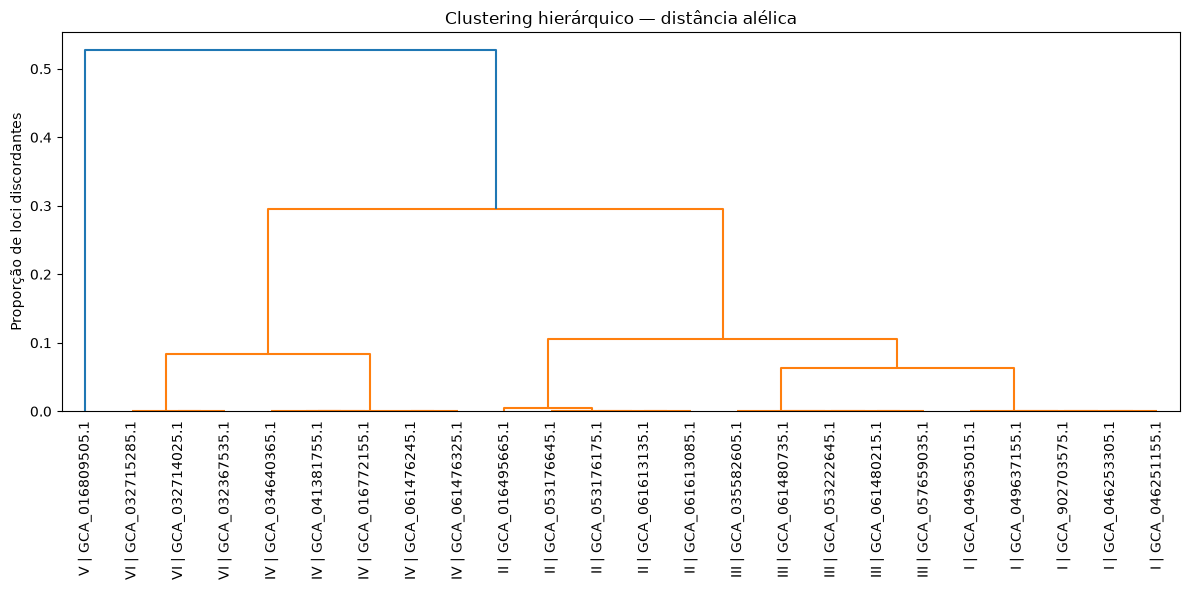

In [65]:
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

X_genotypes = pd.read_parquet(MATRICES_DIR / "X_genotypes.parquet")

# Amostragem por clado
selected = []
for clade, group in sample_metadata_df.groupby("clade_assigned"):
    selected.extend(
        group.sample(n=min(5, len(group)), random_state=SEED).index
    )

# Distância genotípica entre isolados
D = pdist(X_genotypes.loc[selected].to_numpy(), metric="hamming")

# Hierarquia
Z_allelic = linkage(D, method="average")

labels = [
    f"{sample_metadata_df.loc[i, 'clade_assigned']} | {i}"
    for i in selected
]

plt.figure(figsize=(12, 6))
dendrogram(Z_allelic, labels=labels, leaf_rotation=90)
plt.ylabel("Proporção de loci discordantes")
plt.title("Clustering hierárquico — distância alélica")
plt.tight_layout()
plt.show()

In [66]:
from scipy.spatial.distance import pdist, squareform

# Amostragem estratificada
selected = []

for clade, group in sample_metadata_df.groupby("clade_assigned"):
    selected.extend(
        group.sample(
            n=min(20, len(group)),
            random_state=SEED
        ).index
    )

# Distâncias entre genomas
X_sub = X_genotypes.loc[selected].to_numpy(dtype=np.uint8)
D = squareform(pdist(X_sub, metric="hamming"))

labels = sample_metadata_df.loc[selected, "clade_assigned"].to_numpy()

# Matriz de distâncias médias entre clados
clades = sorted(np.unique(labels))

distance_matrix = pd.DataFrame(
    index=clades,
    columns=clades,
    dtype=float
)

for c1 in clades:
    for c2 in clades:
        idx1 = np.where(labels == c1)[0]
        idx2 = np.where(labels == c2)[0]

        if c1 == c2:
            # Distância média intraclado, excluindo a diagonal
            block = D[np.ix_(idx1, idx1)]
            values = block[np.triu_indices(len(idx1), k=1)]
        else:
            # Distância média entre dois clados
            values = D[np.ix_(idx1, idx2)].ravel()

        distance_matrix.loc[c1, c2] = values.mean()

display(distance_matrix.round(4))

/tmp/ipykernel_6265/671637372.py:42: RuntimeWarning: Mean of empty slice
  distance_matrix.loc[c1, c2] = values.mean()
/home/lucas/workspace/projects/clade-clustering/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


,I,II,III,IV,V,VI
I,0.0005,0.1063,0.0634,0.2930,0.5204,0.2932
II,0.1063,0.0015,0.1034,0.3007,0.5266,0.3005
III,0.0634,0.1034,0.0002,0.2923,0.5215,0.2925
IV,0.2930,0.3007,0.2923,0.0004,0.5334,0.0830
V,0.5204,0.5266,0.5215,0.5334,NaN,0.5361
VI,0.2932,0.3005,0.2925,0.0830,0.5361,0.0002


## **5.8 Validação externa: painel de mapeamento (30 genomas)**

Classificamos 30 genomas externos, com clado conhecido (5 por clado), usando o `final_panel` e a `score_samples()` já existentes. Os rótulos da planilha `IDs Cauris.xlsx` servem **apenas para avaliação**: nenhum limiar, marcador ou assinatura é ajustado com eles.

Cuidados de leitura:

- **Imputação REF.** No notebook 03, todo genótipo não chamado (`./.`) e todo locus do Parsnp ausente do VCF externo viraram REF (código `0`). A referência (B11220, GCF_003013715.1) é do **clado II**, então genomas com pouca cobertura tendem a se parecer com o clado II. `called_fraction` (fração dos 97.034 loci com genótipo efetivamente chamado) acompanha cada predição por isso.
- **Clado V.** Os 5 genomas externos do clado V (SRR9007776, SRR18325429–SRR18325432) são os mesmos isolados das amostras SRR hold-out da 5.5.4, aqui obtidos por mapeamento em vez de montagem. Eles não participaram da descoberta, mas não são independentes dessa classificação.

> **Seção opcional.** Depende das matrizes do painel externo geradas na seção 3.5.2 do notebook 03 e da planilha `IDs Cauris.xlsx` em `data/external/mapping_panel/`. Sem esses arquivos, a célula abaixo encerra o notebook aqui; as seções 5.1 a 5.7 não dependem deles.

In [ ]:
class SkipSection(Exception):
    """Encerra o notebook nesta seção exibindo só a mensagem, sem traceback."""

    def _render_traceback_(self):
        return str(self).splitlines()


mapping_panel_inputs = {
    "Matriz externa": X_MAPPING_GENOTYPES_PATH,
    "QC de chamada": MAPPING_QC_PATH,
    "IDs mapping": MAPPING_IDS_PATH,
}

missing_mapping_inputs = [
    (name, path)
    for name, path in mapping_panel_inputs.items()
    if not path.exists()
]

if missing_mapping_inputs:
    details = "\n".join(
        f"- {name}: {path}"
        for name, path in missing_mapping_inputs
    )

    raise SkipSection(
        "Painel externo ausente: seção 5.8 ignorada.\n"
        f"Arquivos não encontrados:\n{details}\n"
        "As seções 5.1 a 5.7 não dependem do painel externo."
    )

print("Painel externo encontrado: executando a validação externa.")

### **5.8.1 Carregamento do painel externo**

In [67]:
X_mapping_genotypes = pd.read_parquet(X_MAPPING_GENOTYPES_PATH)
mapping_qc_df = pd.read_csv(MAPPING_QC_PATH, index_col="sample_id")

mapping_labels = pd.read_excel(MAPPING_IDS_PATH).rename(columns={
    "Sample ID": "sample_id",
    "Clade": "clade_true",
})

assert X_mapping_genotypes.shape == (30, 97034)
assert X_mapping_genotypes.index.is_unique
assert mapping_labels["sample_id"].is_unique
assert set(X_mapping_genotypes.index) == set(mapping_labels["sample_id"])
assert set(X_mapping_genotypes.index) == set(mapping_qc_df.index)
assert mapping_labels["clade_true"].isin(ALL_CLADES).all()

print("X_mapping_genotypes:", X_mapping_genotypes.shape)
display(
    mapping_labels["clade_true"]
    .value_counts()
    .reindex(ALL_CLADES)
    .rename("n_genomes")
    .to_frame()
    .T
)

X_mapping_genotypes: (30, 97034)


clade_true,I,II,III,IV,V,VI
n_genomes,5,5,5,5,5,5


### **5.8.2 Codificação com `encode_genotypes()`**

Cópia literal da função da seção 4.3.2 do notebook 04, incluindo a expansão one-hot dos loci multialélicos e a combinação de colisões por OR lógico. A imputação de `./.` não é refeita: ela já foi aplicada no notebook 03 (hipótese baseline REF).

As colunas codificadas precisam coincidir exatamente com as de `X_encoded`, na mesma ordem, porque `final_panel` indexa as colunas por posição (`marker_idx`). Qualquer diferença interrompe a execução: nenhuma feature é adicionada ou removida.

In [68]:
def encode_genotypes(X_df):
    """
    Bialélicos (0/1): mantém a coluna original.

    Multialélicos (0/1/2/...): expande em colunas binárias por alelo,
    incluindo o alelo de referência (código 0).

    Nomes: chrom:pos_ALELO (ex.: CP043534.1:941787_G).

    Normaliza REF/ALT para maiúsculas.
    Colisões de nomes são combinadas por OR lógico.
    """
    pat = re.compile(r"^(.+):(\d+):([A-Za-z]+)>(.+)$")

    new_cols = {}
    n_bi = n_multi = n_collisions = 0

    for col in X_df.columns:
        match = pat.match(col)

        if match is None:
            raise RuntimeError(f"Identificador de SNP inválido: {col}")

        chrom, pos, ref, alts_str = match.groups()
        alts = alts_str.split(",")

        values = X_df[col].to_numpy()

        if not np.all(values == np.rint(values)):
            raise RuntimeError(f"Códigos não inteiros no locus: {col}")

        if values.min() < 0 or values.max() > len(alts):
            raise RuntimeError(
                f"Códigos fora do intervalo esperado no locus: {col}"
            )

        codes = values.astype(np.int8, copy=False)

        if len(alts) == 1:
            n_bi += 1
            new_cols[col] = codes
            continue

        n_multi += 1

        alleles = [ref.upper()] + [alt.upper() for alt in alts]

        for code, allele in enumerate(alleles):
            key = f"{chrom}:{pos}_{allele}"
            col_bin = (codes == code).astype(np.int8)

            if key in new_cols:
                n_collisions += 1
                new_cols[key] = np.maximum(new_cols[key], col_bin)
            else:
                new_cols[key] = col_bin

    result = pd.DataFrame(new_cols, index=X_df.index)

    print(f"Bialélicos mantidos:      {n_bi:,}")
    print(f"Multialélicos expandidos: {n_multi:,}")
    print(f"Colisões de nomes:        {n_collisions:,}")
    print(f"X_genotypes: {X_df.shape}")
    print(f"X_encoded:   {result.shape}")

    return result

In [69]:
X_mapping_encoded = encode_genotypes(X_mapping_genotypes)

missing_features = X_encoded.columns.difference(X_mapping_encoded.columns)
extra_features = X_mapping_encoded.columns.difference(X_encoded.columns)

if len(missing_features) or len(extra_features):
    raise RuntimeError(
        "Features incompatíveis com X_encoded: "
        f"{len(missing_features)} ausentes no painel externo "
        f"(ex.: {list(missing_features[:3])}), "
        f"{len(extra_features)} extras (ex.: {list(extra_features[:3])})."
    )

if not X_mapping_encoded.columns.equals(X_encoded.columns):
    raise RuntimeError("Mesmas features de X_encoded, mas em ordem diferente.")

X_mapping_arr = X_mapping_encoded.to_numpy(dtype=np.int8, copy=False)

print("X_mapping_encoded:", X_mapping_encoded.shape)
print("Colunas idênticas a X_encoded, na mesma ordem.")

Bialélicos mantidos:      89,933
Multialélicos expandidos: 7,101
Colisões de nomes:        6,006
X_genotypes: (30, 97034)
X_encoded:   (30, 105317)
X_mapping_encoded: (30, 105317)
Colunas idênticas a X_encoded, na mesma ordem.


### **5.8.3 Classificação pelas assinaturas alélicas**

Seis scores por genoma (`score_samples()` com `final_panel`), clado predito pelo maior score e margem entre os dois maiores. Margem `0` indica empate: o `argmax` escolhe o primeiro clado de `ALL_CLADES`, então a predição nesse caso não tem sustentação.

In [77]:
pool_origin = np.concatenate([
    np.repeat("ancoragem", len(y_final_development)),
    np.repeat("expert", len(y_experts)),
])

display(
    pd.crosstab(
        pd.Series(y_pool, name="clado"),
        pd.Series(pool_origin, name="origem do rótulo"),
        margins=True,
        margins_name="total",
    )
)


origem do rótulo,ancoragem,expert,total
clado,,,
I,777,113,890
II,77,6,83
III,212,13,225
IV,33,8,41
V,0,1,1
VI,0,3,3
total,1099,144,1243


In [74]:
final_panel_df

,clade,direction,marker_idx,snp_name,freq_in,freq_out,delta
0,VI,direct,105278,CP043536.1:909780:T>A,1.0,0.0,1.0
1,VI,direct,105236,CP043536.1:909255:A>C,1.0,0.0,1.0
2,VI,direct,105240,CP043536.1:909325:G>A,1.0,0.0,1.0
3,VI,direct,105257,CP043536.1:909600:A>T,1.0,0.0,1.0
4,VI,direct,105157,CP043536.1:778394:C>T,1.0,0.0,1.0
...,...,...,...,...,...,...,...
126200,V,inverse,22338,CP043531.1:2301204_A,0.0,1.0,-1.0
126201,V,inverse,22279,CP043531.1:2297399_T,0.0,1.0,-1.0
126202,V,inverse,22275,CP043531.1:2297188_G,0.0,1.0,-1.0
126203,V,inverse,22273,CP043531.1:2297178_T,0.0,1.0,-1.0


In [1]:
X_mapping_arr

NameError: name 'X_mapping_arr' is not defined

In [76]:
display(score_samples(X_mapping_arr, final_panel, ALL_CLADES))

array([[9.77848113e-01, 2.51399842e-03, 1.15200477e-02, 7.06414212e-05,
        1.94144595e-04, 3.63980507e-05],
       [3.29689294e-01, 3.85555923e-01, 4.92369831e-01, 4.40519929e-01,
        9.77382183e-01, 4.27567869e-01],
       [3.35730731e-01, 3.75728488e-01, 4.91621792e-01, 4.44369882e-01,
        9.90855813e-01, 4.31098491e-01],
       [3.36018413e-01, 3.75728488e-01, 4.91771400e-01, 4.44652438e-01,
        9.91438210e-01, 4.31244075e-01],
       [3.36018413e-01, 3.75499934e-01, 4.91921008e-01, 4.44687754e-01,
        9.91787672e-01, 4.31316882e-01],
       [9.98561561e-01, 2.39972584e-03, 7.48055056e-04, 3.53207106e-05,
        1.35901224e-04, 3.63980507e-05],
       [9.98561561e-01, 2.39972584e-03, 7.48055056e-04, 3.53207106e-05,
        1.16486757e-04, 3.63980507e-05],
       [5.94936728e-01, 4.09096092e-01, 2.10502699e-01, 3.98417637e-02,
        2.53164563e-02, 4.15301733e-02],
       [2.24395856e-01, 4.94114965e-01, 5.02244174e-01, 6.69716001e-01,
        1.90727651e-01, 

In [70]:
scores_external = score_samples(X_mapping_arr, final_panel, ALL_CLADES)
ordered_external = np.sort(scores_external, axis=1)[:, ::-1]

external_predictions_df = pd.DataFrame({
    "sample_id": X_mapping_encoded.index,
    "clade_pred": np.array(ALL_CLADES)[scores_external.argmax(axis=1)],
    "best_score": ordered_external[:, 0],
    "margin": ordered_external[:, 0] - ordered_external[:, 1],
})

for j, clade in enumerate(ALL_CLADES):
    external_predictions_df[f"score_{clade}"] = scores_external[:, j]

external_predictions_df = (
    external_predictions_df
    .merge(
        mapping_labels[["sample_id", "clade_true"]],
        on="sample_id",
        how="left",
        validate="one_to_one",
    )
    .merge(
        mapping_qc_df[["called_fraction"]],
        left_on="sample_id",
        right_index=True,
        how="left",
        validate="one_to_one",
    )
)

external_predictions_df["correct"] = (
    external_predictions_df["clade_true"] == external_predictions_df["clade_pred"]
)

external_predictions_df = external_predictions_df[
    ["sample_id", "clade_true", "clade_pred", "correct", "best_score", "margin"]
    + [f"score_{clade}" for clade in ALL_CLADES]
    + ["called_fraction"]
].sort_values(["clade_true", "called_fraction"]).reset_index(drop=True)

assert external_predictions_df["clade_true"].notna().all()
assert external_predictions_df["called_fraction"].notna().all()

display(external_predictions_df.round(4))

,sample_id,clade_true,clade_pred,correct,best_score,margin,score_I,score_II,score_III,score_IV,score_V,score_VI,called_fraction
0,SRR3883438,I,I,True,0.9986,0.9962,0.9986,0.0024,0.0007,0.0000,0.0001,0.0000,0.1059
1,SRR23696697,I,I,True,0.9986,0.9962,0.9986,0.0024,0.0007,0.0000,0.0001,0.0000,0.1060
2,SRR26666780,I,I,True,0.9986,0.9962,0.9986,0.0024,0.0007,0.0000,0.0001,0.0000,0.1060
3,SRR23696691,I,I,True,0.9986,0.9962,0.9986,0.0024,0.0007,0.0000,0.0001,0.0000,0.1060
4,SRR10851769,I,I,True,0.9778,0.9663,0.9778,0.0025,0.0115,0.0001,0.0002,0.0000,0.1062
5,SRR35767703,II,II,True,1.0000,0.4801,0.0000,1.0000,0.5199,0.0970,0.0580,0.1006,0.0000
6,SRR35767701,II,II,True,1.0000,0.4801,0.0000,1.0000,0.5199,0.0970,0.0580,0.1006,0.0000
7,SRR35767699,II,II,True,1.0000,0.4801,0.0000,1.0000,0.5199,0.0970,0.0580,0.1006,0.0002
8,SRR35767700,II,II,True,1.0000,0.4801,0.0000,1.0000,0.5199,0.0970,0.0580,0.1007,0.0003
9,SRR35767702,II,II,True,1.0000,0.4801,0.0000,1.0000,0.5199,0.0970,0.0580,0.1006,0.0003


In [79]:
# Distância alélica média entre clados (Hamming sobre os 97.034 loci do Parsnp)
X_genotypes = pd.read_parquet(MATRICES_DIR / "X_genotypes.parquet").loc[sample_metadata_df.index]

codes = X_genotypes.to_numpy()
clade_labels = sample_metadata_df["clade_assigned"].to_numpy()
n_codes = int(codes.max()) + 1

# Frequência de cada código alélico (0 = REF, 1 = ALT1, ...) por clado e locus
allele_freq = {
    clade: np.stack([
        (codes[clade_labels == clade] == k).mean(axis=0)
        for k in range(n_codes)
    ])
    for clade in ALL_CLADES
}
n_by_clade = pd.Series(clade_labels).value_counts()

allelic_distance_df = pd.DataFrame(index=ALL_CLADES, columns=ALL_CLADES, dtype=float)

for a in ALL_CLADES:
    for b in ALL_CLADES:
        # Probabilidade, por locus, de dois genomas (um de cada clado) terem alelos diferentes
        mismatch = 1 - (allele_freq[a] * allele_freq[b]).sum(axis=0)
        dist = mismatch.mean()

        if a == b:
            n = n_by_clade[a]
            # Dentro do clado, exclui a comparação de um genoma com ele mesmo
            dist = dist * n / (n - 1) if n > 1 else np.nan

        allelic_distance_df.loc[a, b] = dist

display(allelic_distance_df.round(4))



,I,II,III,IV,V,VI
I,0.0008,0.1066,0.0636,0.2932,0.5206,0.2934
II,0.1066,0.0008,0.1036,0.3008,0.5266,0.3005
III,0.0636,0.1036,0.0003,0.2923,0.5215,0.2925
IV,0.2932,0.3008,0.2923,0.0005,0.5334,0.0830
V,0.5206,0.5266,0.5215,0.5334,NaN,0.5361
VI,0.2934,0.3005,0.2925,0.0830,0.5361,0.0002


| Clado | Distância ao II | ALT esperados (× 97.034) | ALT observados nas externas |
|---|---|---|---|
| I | ≈ 0,106 | ≈ 10.300 | ≈ 10.300 ✓ |
| VI | ≈ 0,30 | ≈ 29.100 | ≈ 29.000 nas 3 completas ✓ |
| VI: SRR24877248 | — | ≈ 29.100 | **6.123** |

> A referência do VCF externo (B11220) é do clado II e o VCF só registra onde a amostra difere dela; por isso a distância de um clado ao II prevê quantos alelos ALT um genoma completo desse clado deve mostrar.


In [80]:
n_alt_parsnp = (
    (X_genotypes != 0)
    .sum(axis=1)
    .groupby(sample_metadata_df["clade_assigned"])
    .agg(["mean", "min", "max"])
    .reindex(ALL_CLADES)
)

display(n_alt_parsnp)


,mean,min,max
clade_assigned,,,
I,15723.986517,15693,20617
II,6047.795181,6006,6663
III,15443.586667,15137,15558
IV,33420.048780,33399,33434
V,53941.000000,53941,53941
VI,33372.000000,33369,33374


### **5.8.4 Métricas de classificação**

In [71]:
y_external_true = external_predictions_df["clade_true"]
y_external_pred = external_predictions_df["clade_pred"]

print(f"Accuracy:          {accuracy_score(y_external_true, y_external_pred):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_external_true, y_external_pred):.4f}")

external_report_df = pd.DataFrame(
    classification_report(
        y_external_true,
        y_external_pred,
        labels=ALL_CLADES,
        zero_division=0,
        output_dict=True,
    )
).T

display(external_report_df.loc[ALL_CLADES, ["precision", "recall", "f1-score", "support"]].round(3))

external_cm_df = pd.DataFrame(
    confusion_matrix(y_external_true, y_external_pred, labels=ALL_CLADES),
    index=[f"real_{c}" for c in ALL_CLADES],
    columns=[f"pred_{c}" for c in ALL_CLADES],
)

display(external_cm_df)

Accuracy:          0.9667
Balanced accuracy: 0.9667


,precision,recall,f1-score,support
I,0.833,1.0,0.909,5.0
II,1.000,1.0,1.000,5.0
III,1.000,1.0,1.000,5.0
IV,1.000,1.0,1.000,5.0
V,1.000,1.0,1.000,5.0
VI,1.000,0.8,0.889,5.0


,pred_I,pred_II,pred_III,pred_IV,pred_V,pred_VI
real_I,5,0,0,0,0,0
real_II,0,5,0,0,0,0
real_III,0,0,5,0,0,0
real_IV,0,0,0,5,0,0
real_V,0,0,0,0,5,0
real_VI,1,0,0,0,0,4


- **Desempenho e cobertura por clado**

Acertos e margem lado a lado com a cobertura dos 5 genomas de cada clado. Um acerto com `called_fraction` próxima de zero não é evidência a favor da assinatura: pode refletir apenas a imputação REF.

In [72]:
external_coverage_summary_df = (
    external_predictions_df
    .groupby("clade_true")
    .agg(
        n_genomes=("sample_id", "size"),
        n_correct=("correct", "sum"),
        mean_margin=("margin", "mean"),
        min_called_fraction=("called_fraction", "min"),
        mean_called_fraction=("called_fraction", "mean"),
        max_called_fraction=("called_fraction", "max"),
    )
    .reindex(ALL_CLADES)
)

display(external_coverage_summary_df.round(4))

,n_genomes,n_correct,mean_margin,min_called_fraction,mean_called_fraction,max_called_fraction
clade_true,,,,,,
I,5,5,0.9902,0.1059,0.1060,0.1062
II,5,5,0.4801,0.0000,0.0002,0.0003
III,5,5,0.8781,0.1032,0.1032,0.1032
IV,5,5,0.1248,0.2394,0.2451,0.2508
V,5,5,0.4947,0.5144,0.5196,0.5223
VI,5,4,0.1505,0.0631,0.2377,0.2992


In [73]:
CV_DIR.mkdir(parents=True, exist_ok=True)

external_predictions_df.to_csv(EXTERNAL_PREDICTIONS_PATH, index=False)

print(f"Predições externas salvas em: {EXTERNAL_PREDICTIONS_PATH}")

Predições externas salvas em: /home/lucas/workspace/projects/clade-clustering/data/results/v4/signature_cross_validation/external_panel_predictions.csv
